In [1]:
from pathlib import Path
import hashlib, json, zipfile
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import yaml
from IPython.display import display, Markdown

WORK = Path('/kaggle/working')
WORK.mkdir(parents=True, exist_ok=True)
def dataset_file(name):
    matches = sorted(Path('/kaggle/input').rglob(name))
    assert len(matches) == 1, f'Expected one attached {name}: {matches}'
    return matches[0]
A = dataset_file('task_soundness.csv').parent
K = dataset_file('gate_measurements.csv').parent
for folder in [A, K]:
    manifest = json.loads((folder/'manifest.json').read_text())
    for f in manifest['files']:
        assert hashlib.sha256((folder/f['name']).read_bytes()).hexdigest() == f['sha256'], f['name']
audit = pd.read_csv(A/'task_soundness.csv')
runs = pd.read_csv(A/'local_agent_results.csv')
summary = pd.read_csv(A/'series_summary.csv')
runtime = pd.read_csv(A/'runtime_scenarios.csv')
gate = pd.read_csv(K/'gate_measurements.csv').set_index('measurement')['value']
protocol = json.loads((A/'protocol.json').read_text())
assert len(audit)==129 and audit.task_id.is_unique and audit.sound.sum()==114
assert len(runs)==177 and not runs.duplicated(['series','task_id']).any()
assert set(runs.task_id) == set(audit.task_id)
assert not set(audit.query("split == 'development'").repo) & set(audit.query("split == 'held_out'").repo)
plt.rcParams.update({'font.family':'DejaVu Sans','font.size':11,'axes.spines.top':False,'axes.spines.right':False,'axes.titleweight':'bold','axes.titlelocation':'left','axes.labelcolor':'#253b4a','text.color':'#253b4a','axes.edgecolor':'#bbc6ca','figure.facecolor':'#ffffff','axes.facecolor':'#ffffff','savefig.facecolor':'#ffffff'})
TEAL, BLUE, AMBER, RED, GRAY = '#23877c','#447da9','#c18d43','#bd625c','#d5dee1'
def save(fig, name):
    fig.savefig(WORK/name, dpi=175, bbox_inches='tight')
    plt.show()
    plt.close(fig)

render_checks = pd.read_csv(K/'served_prompt_checks.csv')
nll = pd.read_csv(A/'lora_debug_nll.csv')
debug = json.loads((A/'lora_debug_verdict.json').read_text())
errors = pd.read_csv(A/'rollout_error_taxonomy.csv')
assert errors['count'].sum() == 118 and set(errors.total_rollouts) == {280}
assert debug['verdict'] == 'NO-GO'
assert not nll.duplicated(['cohort','span']).any() and not nll.isna().any().any()
assert not render_checks.duplicated(['cohort','rendering','check']).any()

paired = pd.read_csv(A/'local_paired_eval.csv')
lb = pd.read_csv(A/'lb_submission_history.csv')
paired_protocol = json.loads((A/'paired_eval_protocol.json').read_text())
assert len(paired)==228 and not paired.isna().any().any()
assert not paired.duplicated(['config','split','task_id']).any()
assert set(paired.task_id)==set(audit.query('sound == 1').task_id)
assert set(lb.submission_ref)=={56551395,56583842,56700442,56789168,56842963,56864695}


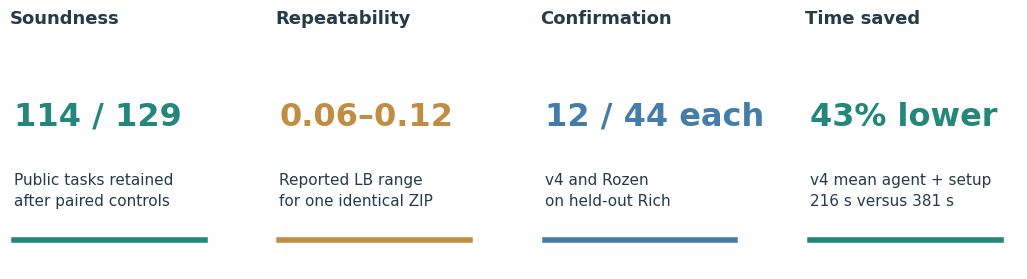

In [2]:
fig, axs = plt.subplots(1,4,figsize=(13,3.3))
items = [
    ('Soundness', '114 / 129', 'Public tasks retained\nafter paired controls', TEAL),
    ('Repeatability', '0.06–0.12', 'Reported LB range\nfor one identical ZIP', AMBER),
    ('Confirmation', '12 / 44 each', 'v4 and Rozen\non held-out Rich', BLUE),
    ('Time saved', '43% lower', 'v4 mean agent + setup\n216 s versus 381 s', TEAL),
]
for ax,(title,value,detail,color) in zip(axs,items):
    ax.axis('off');ax.set_title(title,fontsize=13,pad=15)
    ax.text(.02,.64,value,fontsize=23,fontweight='bold',color=color,transform=ax.transAxes)
    ax.text(.02,.28,detail,fontsize=11,linespacing=1.5,transform=ax.transAxes)
    ax.plot([.02,.92],[.13,.13],color=color,lw=4,transform=ax.transAxes)
fig.subplots_adjust(wspace=.25,top=.8,bottom=.12)
save(fig, '01_graphical_abstract.png')


*Figure 1. Measure before selecting: task controls, observed archive repeatability, repository-separated confirmation and measured time. The 0.12 reference score is Roman Rozen's author report; 0.10 and 0.06 are our verified repeats. Sources: `task_soundness.csv`, `lb_submission_history.csv`, `local_paired_eval.csv` and `paired_eval_protocol.json` in the attached datasets.*

## 1. Establish which tasks measure a fix

A sound local task should fail with an empty patch and pass with its reference patch, with neither control reporting an error. We ran both controls for all 129 tasks. Dependency-only repairs restored seven Rich environments using their snapshot-pinned Pygments version and two FastAPI environments using declared optional JSON dependencies. The tests, patches and scoring logic remained unchanged.

The final controls produce **119 reference passes** and **2 empty passes**. Soundness also excludes control errors: three Rich empty controls time out despite passing reference controls, and required skipped tests are retained as exclusions. This yields **114 sound tasks and 15 exclusions**. The [official harness](https://www.kaggle.com/competitions/gemma-4-developer-agent/data?select=HARNESS_README.md) supplies the evaluator; our mask is specific to the frozen local environment.


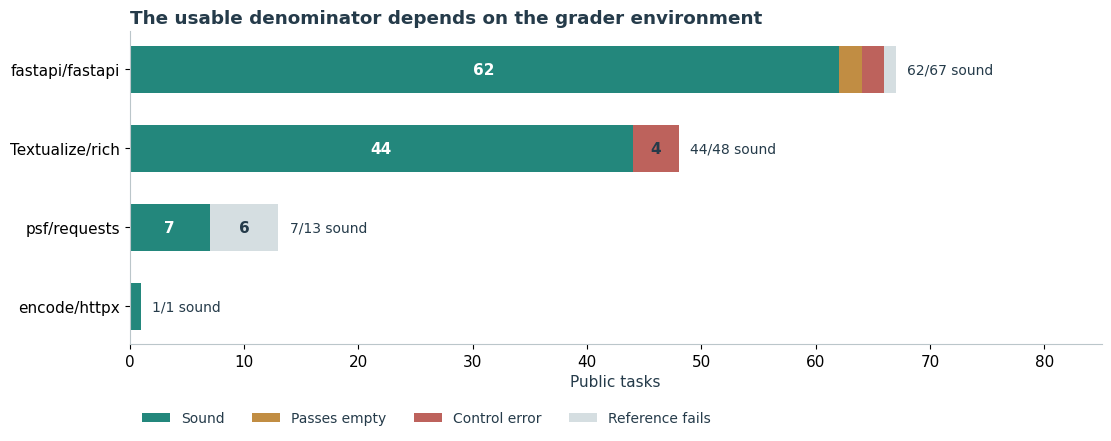

table,rows,duplicate keys,missing task IDs,missing test exit codes
Task audit,129,0,0,0
Agent measurements,177,0,0,62


In [3]:
order=['fastapi/fastapi','Textualize/rich','psf/requests','encode/httpx']
statuses=['sound','passes_without_fix','control_error','gold_does_not_pass_local_grader']
labels=['Sound','Passes empty','Control error','Reference fails']
counts=pd.crosstab(audit.repo,audit.status).reindex(index=order,columns=statuses,fill_value=0)
fig,ax=plt.subplots(figsize=(11,4.3),layout='constrained')
left=np.zeros(len(order))
for status,label,color in zip(statuses,labels,[TEAL,AMBER,RED,GRAY]):
    vals=counts[status].to_numpy();ax.barh(order,vals,left=left,label=label,color=color,height=.60)
    for i,v in enumerate(vals):
        if v>=3:ax.text(left[i]+v/2,i,str(v),ha='center',va='center',color='white' if status=='sound' else '#253b4a',weight='bold')
    left+=vals
for i,repo in enumerate(order):ax.text(left[i]+1,i,f"{counts.loc[repo,'sound']}/{int(left[i])} sound",va='center',fontsize=10)
ax.invert_yaxis();ax.set_xlim(0,85);ax.set_xlabel('Public tasks');ax.set_title('The usable denominator depends on the grader environment')
ax.legend(ncol=4,loc='lower left',bbox_to_anchor=(0,-.30),frameon=False,fontsize=10)
save(fig,'02_soundness.png')
quality=pd.DataFrame({'table':['Task audit','Agent measurements'],'rows':[len(audit),len(runs)],'duplicate keys':[audit.task_id.duplicated().sum(),runs.duplicated(['series','task_id']).sum()],'missing task IDs':[audit.task_id.isna().sum(),runs.task_id.isna().sum()],'missing test exit codes':[audit[['empty_exit_code','gold_exit_code']].isna().sum().sum(),(runs.test_exit_code.eq(-1) | runs.test_exit_code.isna()).sum()]})
display(quality.style.hide(axis='index'))


*Figure 2. FastAPI contributes 62/67 sound tasks, Rich 44/48, Requests 7/13 and HTTPX 1/1. The audit CSV preserves every exclusion reason and both control outcomes. The run table has no blank cells; 62 unavailable verifier exit codes use the recorded sentinel -1. They are not successes or zero-valued timings.*

The repository split assigns FastAPI, Requests and HTTPX to development (**81 tasks, 70 sound**) and Rich to held-out evaluation (**48 tasks, 44 sound**). Each audit identifier and each task–run pair is unique. Repository overlap across splits is zero. Rich is nevertheless only one held-out repository, and the competition's approximately 120 test tasks come from private repositories: this split does not establish performance under that domain shift. [Official data description](https://www.kaggle.com/competitions/gemma-4-developer-agent/data).

For a concrete reading of the table, `fastapi_11194` is sound because empty fails and reference passes. `fastapi_14077` passes without a fix, so it is excluded. `rich_3480` has a timed-out empty control and remains excluded even though its reference passes. These identifiers are join keys; task text and patches must be obtained from the official competition input.

## 2. Historical comparison: September 30

These September 30 runs use the older request path and differ from the seed-controlled October comparison in section 10. Their outcomes remain separate.

The frozen **v4 single agent** has a five-minute cap and 20 tool calls. The **coder + analyzer baseline** gives a coder a separate analysis tool, with an eight-minute cap and 100 tool calls. Both use the required base model with prompt and tool configuration only; neither includes trained weights. Their historical budgets differ, so this comparison measures complete designs rather than the causal effect of adding an analyzer.

We evaluated all 48 held-out tasks for each design, then applied the mask fixed before comparison. The sound-task counts are **14/44 for v4** and **13/44 for coder + analyzer**. Nine successes overlap; five are unique to v4 and four to the baseline. On development, the baseline resolves **15/70** sound tasks: FastAPI 11/62, Requests 3/7, HTTPX 1/1. Errors remain in the denominator.


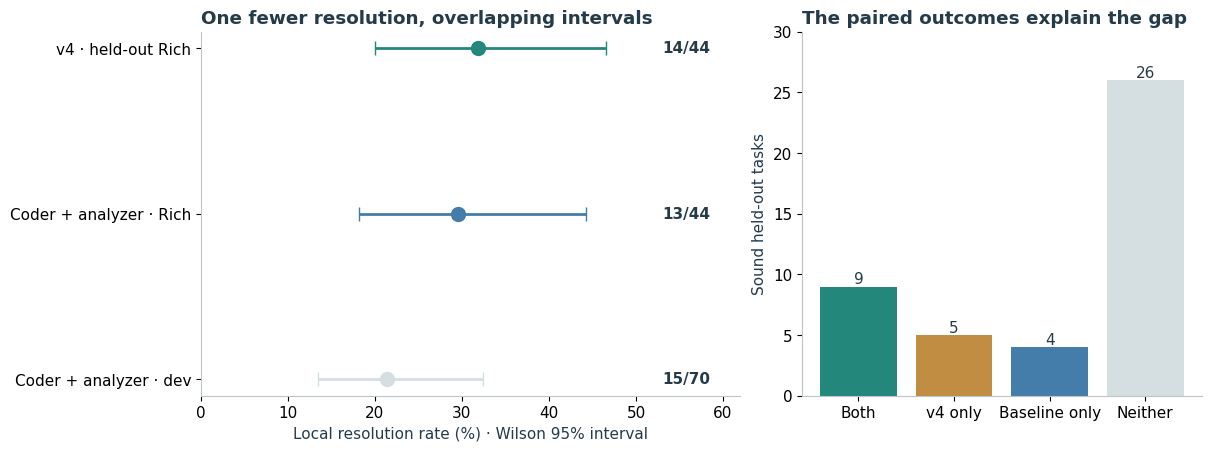

In [4]:
s=summary.query("cohort == 'sound_tasks'").set_index('series')
names=['20260930-v4-heldout','20260930-baseline-heldout','20260930-baseline-development']
fig,(ax,bx)=plt.subplots(1,2,figsize=(12,4.4),gridspec_kw={'width_ratios':[1.35,1]},layout='constrained')
for i,(name,color) in enumerate(zip(names,[TEAL,BLUE,GRAY])):
    r=s.loc[name];ax.errorbar(r['rate']*100,i,xerr=[[100*(r['rate']-r.wilson_low)],[100*(r.wilson_high-r['rate'])]],fmt='o',color=color,ms=10,capsize=5,lw=2)
    ax.text(53,i,f'{int(r.resolved)}/{int(r.n)}',va='center',weight='bold')
ax.set_yticks(range(3),['v4 · held-out Rich','Coder + analyzer · Rich','Coder + analyzer · dev'])
ax.invert_yaxis();ax.set_xlim(0,62);ax.set_xlabel('Local resolution rate (%) · Wilson 95% interval');ax.set_title('One fewer resolution, overlapping intervals')
p=protocol['paired_sound_heldout']; vals=[p['both'],len(p['v4_only']),len(p['baseline_only']),p['neither']]
bx.bar(['Both','v4 only','Baseline only','Neither'],vals,color=[TEAL,AMBER,BLUE,GRAY]);bx.bar_label(bx.containers[0]);bx.set_ylim(0,30);bx.set_ylabel('Sound held-out tasks');bx.set_title('The paired outcomes explain the gap')
save(fig,'03_resolution.png')


*Figure 3. Historical September 30 results. Task-level Wilson 95% intervals are 20.0–46.6% for v4, 18.2–44.2% for the held-out baseline and 13.4–32.4% for development. They ignore within-repository correlation and therefore should not be read as cross-repository generalization intervals. Sources: `series_summary.csv` and `protocol.json`.*

The baseline declares seed 42 in YAML, but the installed Agent Development Kit (ADK) conversion omitted that seed from outgoing model requests. The runs are therefore neither deterministic nor matched-seed experiments. Aggregate held-out results informed this report; held-out failure content was not used for prompt selection or training. The October protocol in section 10 fixes the effective request seed; differing bundle budgets still prevent a single-component causal claim.

## 3. Historical timing: price an experiment in seconds

On sound Rich tasks, mean agent-plus-setup time is **228.0 seconds for v4** and **402.9 seconds for the baseline**; mean tool calls are **10.4** and **21.2**. The more expensive design resolves one fewer task in this frozen comparison. Wall time covers setup, agent work and cleanup; local patch grading is excluded to match the competition's stated budget scope. Across all 129 baseline tasks, the mean is **415.0 seconds** and the maximum **584.7 seconds**.

The official allowance is **12 hours including sandbox setup and excluding validation**. Four L4 GPUs form one tensor-parallel (TP4) model in the published configuration. They do not imply four independent task workers. Our measurements come from one A100 with TP1; the L4 slowdown below is an assumption, not a benchmark. [Evaluation budget](https://www.kaggle.com/competitions/gemma-4-developer-agent/overview/evaluation) · [Serving guide](https://www.kaggle.com/competitions/gemma-4-developer-agent/data?select=HARNESS_README.md).


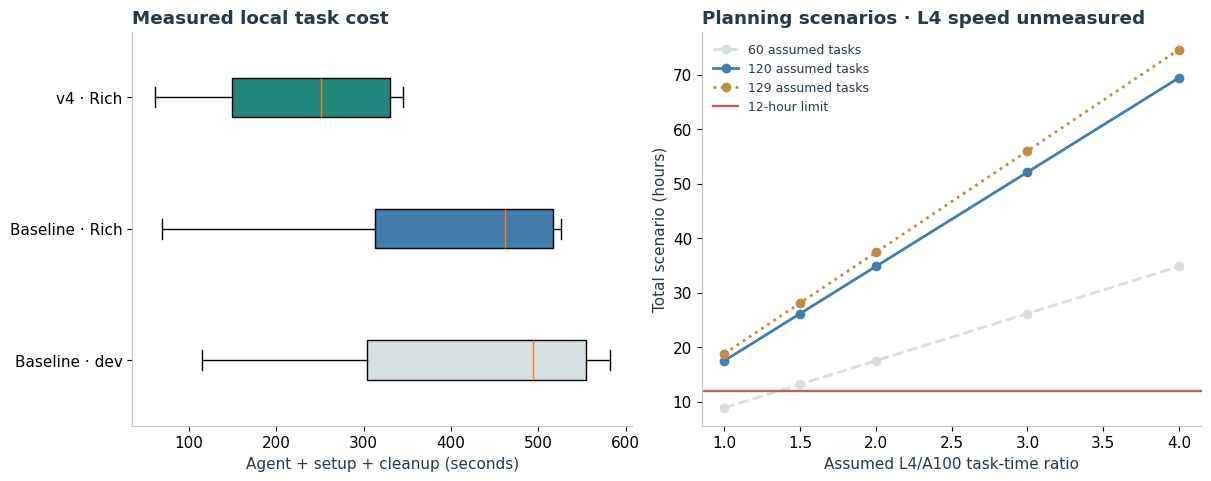

In [5]:
fig,(ax,bx)=plt.subplots(1,2,figsize=(12,4.7),layout='constrained')
groups=[runs.query('sound == 1 and series == @n').agent_and_setup_seconds.to_numpy() for n in names]
bp=ax.boxplot(groups,vert=False,patch_artist=True,showfliers=False)
ax.set_yticks([1,2,3],['v4 · Rich','Baseline · Rich','Baseline · dev'])
for box,color in zip(bp['boxes'],[TEAL,BLUE,GRAY]):box.set_facecolor(color)
ax.invert_yaxis();ax.set_xlabel('Agent + setup + cleanup (seconds)');ax.set_title('Measured local task cost')
for tasks,color,style in [(60,GRAY,'--'),(120,BLUE,'-'),(129,AMBER,':')]:
    r=runtime.query('assumed_tasks == @tasks');bx.plot(r.assumed_l4_slowdown,r.scenario_hours,label=f'{tasks} assumed tasks',color=color,ls=style,marker='o',lw=2)
bx.axhline(12,color=RED,lw=1.7,label='12-hour limit');bx.set_xlabel('Assumed L4/A100 task-time ratio');bx.set_ylabel('Total scenario (hours)');bx.set_title('Planning scenarios · L4 speed unmeasured');bx.legend(frameon=False,fontsize=9)
save(fig,'04_runtime.png')


*Figure 4. Historical September 30 timing and uncalibrated scenarios. Left: measured distributions on the sound subsets, with medians, interquartile ranges and whiskers within 1.5 interquartile ranges. Right: `(900 + tasks × 414.966 × slowdown × 1.25) / 3600`, using a 15-minute startup allowance and 25% task-time margin. Sources: `local_agent_results.csv` and `runtime_scenarios.csv`.*

For the organizer's approximate **120-task total**, the baseline scenario is **17.54 hours even at an assumed 1× ratio**, and **34.83 hours at 2×**. With the same startup and margin, 12 hours allow about **282 seconds of uninflated task time** per task. A per-task cap alone does not guarantee the total: setup and cleanup consume time, and context overflows or timeouts can spend the budget without returning a useful patch. Hardware calibration and a total-workload dry run are more informative than a larger nominal tool budget.

## 4. Verify that LoRA changes inference

LoRA adds a low-rank update, `ΔW = (alpha / rank) × B × A`, to a base projection. The two official example adapters we inspected have identical weights and zero B tensors. Their zero update is useful as a loading control, but cannot demonstrate nonzero adaptation. The model checkpoint uses quantization-aware training (QAT); the exact serving build matters alongside the adapter configuration. [LoRA paper](https://arxiv.org/abs/2106.09685) · [Official wheelhouse](https://www.kaggle.com/datasets/metric/gemma-4-developer-agent-wheelhouse).

An earlier serving path registered each decoder layer under two names. Adapter activation loaded the canonical name, then reset the same module through an alias without matching weights. The inspected competition wheel avoids that duplicate registration when fast prefill is disabled. The organizer reports that the fix landed in wheelhouse v23. Our result below is tied to its recorded wheel hash, rather than a claim that the present wheelhouse still has the defect. [Alias report and organizer response](https://www.kaggle.com/competitions/gemma-4-developer-agent/discussion/743508) · [Earlier startup/routing discussion](https://www.kaggle.com/competitions/gemma-4-developer-agent/discussion/743213).

The strong diagnostic uses **untrained rank-4, alpha-8 weights on 410 projections**. We warm base, zero-adapter and strong-adapter routes, then issue base/zero/strong/base requests with temperature 0 and seed 42 explicitly on the wire. Repeated base and zero control agree exactly. Warmup drift reaches **0.125 nats**, making the frozen ten-times-noise threshold **1.25 nats**. The strong adapter changes the output and removes the base-leading token from its first-token top 20; the resulting decrease is **at least 4.8921 nats**. A nat is one unit of natural-log probability.


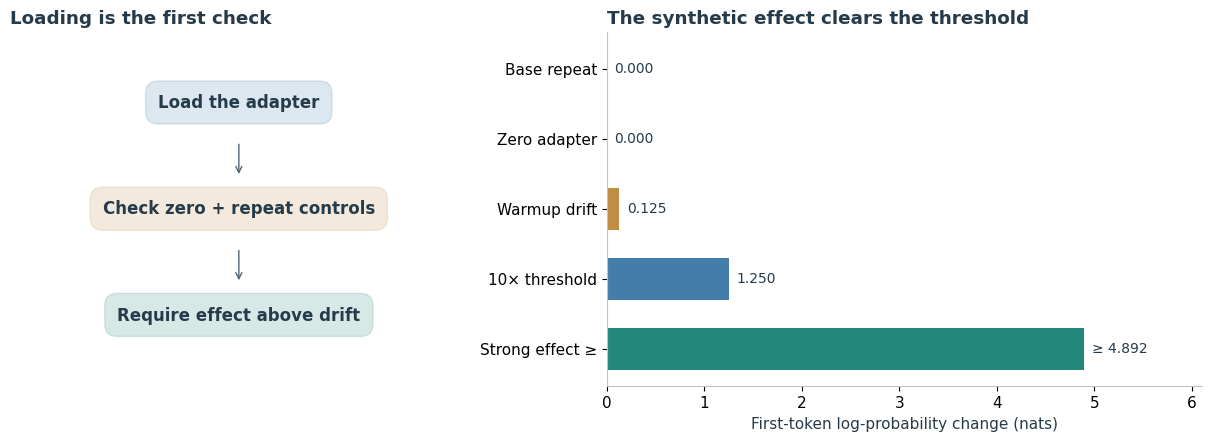

**CPU replay of the saved effect evidence: PASS.**

In [6]:
fig,(ax,bx)=plt.subplots(1,2,figsize=(12,4.3),gridspec_kw={'width_ratios':[1,1.3]},layout='constrained')
ax.axis('off')
for y,label,color in [(.8,'Load the adapter',BLUE),(.5,'Check zero + repeat controls',AMBER),(.2,'Require effect above drift',TEAL)]:
    ax.text(.5,y,label,ha='center',va='center',fontsize=12,weight='bold',bbox={'boxstyle':'round,pad=.75','facecolor':color,'alpha':.18,'edgecolor':color},transform=ax.transAxes)
for y in [.69,.39]:ax.annotate('',xy=(.5,y-.1),xytext=(.5,y),xycoords='axes fraction',arrowprops={'arrowstyle':'->','color':'#526574'})
ax.set_title('Loading is the first check')
keys=['base_repeat_drift','zero_adapter_drift','warmup_drift','effect_threshold','strong_effect_lower_bound']
vals=[gate[k] for k in keys]
bars=bx.barh(['Base repeat','Zero adapter','Warmup drift','10× threshold','Strong effect ≥'],vals,color=[GRAY,GRAY,AMBER,BLUE,TEAL],height=.6)
for i,v in enumerate(vals):bx.text(v+.08,i,('≥ ' if i==4 else '')+f'{v:.3f}',va='center',fontsize=10)
bx.invert_yaxis();bx.set_xlim(0,6.1);bx.set_xlabel('First-token log-probability change (nats)');bx.set_title('The synthetic effect clears the threshold')
save(fig,'05_lora_gate.png')
import runpy
probe=runpy.run_path(str(K/'probe_adapter_effect.py'))
replayed=probe['assess'](json.loads((K/'probe_top20.json').read_text()))
assert replayed['pass'] and replayed['missing_token_drop_lower_bound'] > replayed['threshold']
display(Markdown('**CPU replay of the saved effect evidence: PASS.**'))


*Figure 5. The final bar is a conservative lower bound inferred from top-20 membership, not an exactly aligned token delta. The notebook replays that calculation from the attached first-token distributions. This is an inference-effect diagnostic; the synthetic adapter is deliberately untrained and is never packaged as a candidate.*

The successful path uses the competition vLLM **0.19.1** wheel, transformers **5.13.1**, compressed-tensors **0.15.0.1**, torch **2.10.0**, adk-submission **0.2.11** and swegemma **0.2.7**, with 257 frozen compatible packages. The complete historical wheelhouse could not be installed together because of a Starlette dependency conflict; the kit records the compatible lock and exact official wheel hashes. A cluster-specific device-UUID adjustment touched platform plumbing, not model or LoRA code. The private image and TP4 L4 behavior remain unmeasured.

For reproduction, start with the [serving and verification kit](https://www.kaggle.com/datasets/dmitriigluzdov/gemma-4-serving-and-lora-verification-kit): its CPU replay needs no accelerator; its live probe operates on a separately started, user-owned server. The kit also explains why the adapter map must be nonempty for this ADK version to emit LoRA flags. A trained adapter still needs save/reload checks, long-context memory tests and a matched task comparison after this serving gate.



## 5. Train on the prompt the server actually sees

ADK replays earlier thoughts in `reasoning_content`. In the inspected vLLM 0.19.1 path, `chat_utils` reads `reasoning` instead. The recorded server prompts therefore contain the issue, tools and tool-call history **without past thoughts**. A second detail also matters: vLLM wraps string content as text parts before applying the template. Together, these two changes reproduce **803/803 native** and **133/133 held-out Rich** prompt lengths; the old renderer reproduces **0/803**. Dropping thoughts alone also matches zero; content parts alone match 79 first turns.

This mechanism was already reported by KE WU in [discussion 744354](https://www.kaggle.com/competitions/gemma-4-developer-agent/discussion/744354). Our contribution is the aggregate ablation, 936-turn length check and reusable reference. The organizer's October 1 reply says the fix should be in the current wheelhouse; September 29 also states that all old submissions cannot be rescored. **The reference documents our historical stack. Recheck the deployed wheels before rendering new training data.**


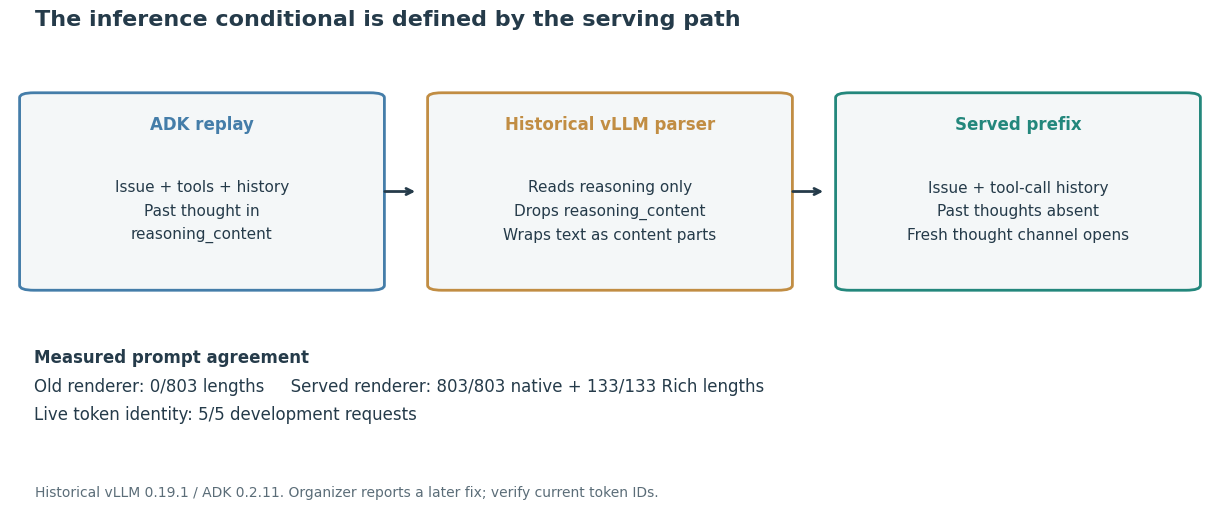

,cohort,rendering,check,matches,checked
0,native,old_history,prompt_token_count,0,803
1,native,drop_reasoning_content_only,prompt_token_count,0,803
2,native,content_parts_only,prompt_token_count,79,803
3,native,served_history,prompt_token_count,803,803
4,held_out_rich,served_history,prompt_token_count,133,133
5,development_live_probe,served_history,prompt_token_identity,5,5
6,native,reconstructed_target,prompt_and_completion_token_count,765,803


In [7]:
from matplotlib.patches import FancyBboxPatch
fig = plt.figure(figsize=(12.5,5.1))
ax = fig.add_axes([.02,.08,.96,.80]);ax.set_xlim(0,1);ax.set_ylim(0,1);ax.axis('off')
boxes=[(.02, 'ADK replay', 'Issue + tools + history\nPast thought in\nreasoning_content', BLUE),
       (.36, 'Historical vLLM parser', 'Reads reasoning only\nDrops reasoning_content\nWraps text as content parts', AMBER),
       (.70, 'Served prefix', 'Issue + tool-call history\nPast thoughts absent\nFresh thought channel opens', TEAL)]
for x,head,body,color in boxes:
    ax.add_patch(FancyBboxPatch((x,.45),.28,.46,boxstyle='round,pad=0.012',facecolor='#f4f7f8',edgecolor=color,lw=2))
    ax.text(x+.14,.83,head,ha='center',weight='bold',fontsize=12,color=color)
    ax.text(x+.14,.63,body,ha='center',va='center',fontsize=11,linespacing=1.7)
for start,end in [(.31,.34),(.65,.68)]:
    ax.annotate('',xy=(end,.68),xytext=(start,.68),arrowprops={'arrowstyle':'->','color':'#253b4a','lw':2})
ax.text(.02,.26,'Measured prompt agreement',weight='bold',fontsize=12)
ax.text(.02,.12,'Old renderer: 0/803 lengths     Served renderer: 803/803 native + 133/133 Rich lengths\nLive token identity: 5/5 development requests',fontsize=12,linespacing=1.7)
fig.suptitle('The inference conditional is defined by the serving path',x=.04,ha='left',weight='bold',fontsize=16)
fig.text(.04,.025,'Historical vLLM 0.19.1 / ADK 0.2.11. Organizer reports a later fix; verify current token IDs.',fontsize=10,color='#5b6d78')
save(fig,'06_served_prompt.png')
display(render_checks.rename(columns={'matched':'matches','total':'checked'}))


*Figure 6. The historical field mismatch removes past reasoning while preserving tool history. Only the five-request live probe checks token identity; the 936-turn result checks prompt lengths. Source: `served_prompt_checks.csv` and `served_render_reference.py` in the serving kit, derived from `research/LORA_DATA_PLAN_20261002.md` §A and `scripts/cluster-debug-iter1/served_render.py`; their hashes are recorded in `source_lineage.json`.*

An empty target thought is another trap. After a tool response, the generation prefix opens `thought`; an empty thought must still close that channel before the action. Rendering a completed assistant message with empty reasoning can skip that opening and violate prefix matching. Reconstructed prompt **and completion** lengths match in **765/803** native turns; exact served token IDs provide a stronger admission rule because text can re-tokenize differently even at the same length. Supervised fine-tuning (SFT) should preserve this per-turn inference conditional and test joint encoding, rather than assuming a whole-trajectory template is equivalent.

The same check changes the external-data decision. Our inspected **150 SWE-smith trajectories** use `bash`, `str_replace_editor` and `submit`, whereas this harness expects `run_command`, `read_file`, `edit_file` and `submit_patch`. Their observations differ, historical thoughts were retained and success labels were not regraded. The native baseline already produces **0 unknown-tool calls in 3,328 tool-call turns**. Those demonstrations are a poor fit for this SFT mix without new execution and grading; this is a sample-specific finding. The kit's `external_trajectory_assessment.json` provides the aggregate evidence from the data plan's section B.

## 6. Use an unresolved-trace control before trusting a loss reduction

Negative log-likelihood (NLL) measures how much probability the model assigns to the recorded target tokens. It is useful for debugging, but a model trained on its own successful traces can become more confident in its existing style without becoming a better repair agent. We test this with both resolved and unresolved Rich traces and a resolved set from the different coder/analyzer design.

The debug adapter uses rank 16, alpha 32, learning rate 1e-4 and seed 42. Training admits **412 turns from 23 development tasks**, caps sequences at 8,192 tokens, excludes Rich and three development-validation tasks, and runs 30 optimizer steps with accumulation eight. The supervised data are mostly thoughts: 97,829 thought tokens and 19,464 action tokens. The final adapter reduces Rich action NLL by **40.7%** and thought NLL by **25.5%**.


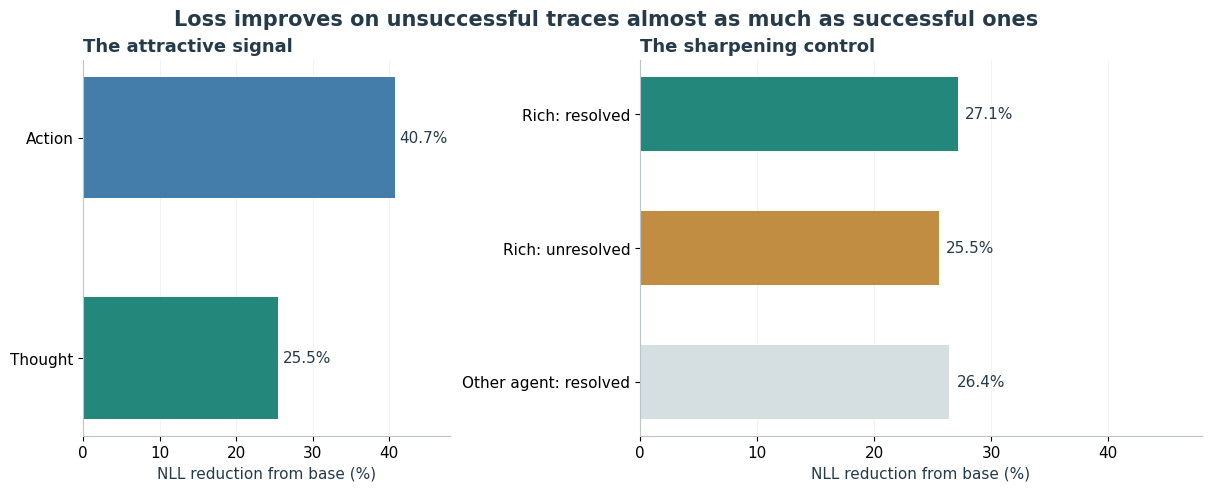

,Check,Base or mid,Final adapter,Interpretation
0,Rich overall NLL (nats/token),0.067791,0.073424,Final worse than mid: FAIL
1,Resolved / 32 local runs,4.000000,2.000000,Allowed loss at most one: FAIL
2,Mean agent wall time ratio,1.000000,1.017478,Within +10%: PASS
3,Completion tokens per turn ratio,1.000000,1.036725,Within +10%: PASS


In [8]:
fig,(ax,bx)=plt.subplots(1,2,figsize=(12,4.8),layout='constrained',gridspec_kw={'width_ratios':[.85,1.3]})
span=nll.query("cohort == 'rich_resolved' and span != 'overall'").set_index('span')
ax.barh(['Action','Thought'],[-span.loc['action','relative_change_pct'],-span.loc['thought','relative_change_pct']],color=[BLUE,TEAL],height=.55)
ax.invert_yaxis();ax.set_title('The attractive signal',fontsize=13)
controls=nll.query("span == 'overall' and cohort != 'development_validation'").set_index('cohort')
cohorts=['rich_resolved','rich_unresolved','coder_analyzer_resolved']
values=[-controls.loc[x,'relative_change_pct'] for x in cohorts]
bx.barh(['Rich: resolved','Rich: unresolved','Other agent: resolved'],values,color=[TEAL,AMBER,GRAY],height=.55)
bx.invert_yaxis();bx.set_title('The sharpening control',fontsize=13)
for panel in [ax,bx]:
    panel.set_xlim(0,48);panel.set_xlabel('NLL reduction from base (%)')
    panel.grid(axis='x',alpha=.15);panel.set_axisbelow(True)
    for bar in panel.patches:
        panel.text(bar.get_width()+.6,bar.get_y()+bar.get_height()/2,f'{bar.get_width():.1f}%',va='center',fontsize=11)
fig.suptitle('Loss improves on unsuccessful traces almost as much as successful ones',fontsize=15,weight='bold')
save(fig,'07_sharpening_control.png')
criteria=debug['criteria']
display(pd.DataFrame([
 {'Check':'Rich overall NLL (nats/token)','Base or mid':criteria['final_not_worse_than_mid_on_rich']['mid'],'Final adapter':criteria['final_not_worse_than_mid_on_rich']['final'],'Interpretation':'Final worse than mid: FAIL'},
 {'Check':'Resolved / 32 local runs','Base or mid':4,'Final adapter':2,'Interpretation':'Allowed loss at most one: FAIL'},
 {'Check':'Mean agent wall time ratio','Base or mid':1,'Final adapter':criteria['agent_wall_time_within_10pct']['ratio'],'Interpretation':'Within +10%: PASS'},
 {'Check':'Completion tokens per turn ratio','Base or mid':1,'Final adapter':criteria['completion_tokens_per_turn_within_10pct']['ratio'],'Interpretation':'Within +10%: PASS'}]))


*Figure 7. Left: span-specific loss reductions on resolved Rich turns. Right: overall reductions of **27.1%** on resolved Rich, **25.5%** on unresolved Rich and **26.4%** on the other agent's resolved traces. The 1.6-percentage-point resolved/unresolved gap is small and has no reported uncertainty estimate; the reductions mainly support broad sharpening, not a demonstrated quality gain. Sources: `lora_debug_nll.csv` and `lora_debug_verdict.json`, derived from `experiments/runs/20261002-fable-debug-iter1/verdict.json`.*

The registered gate returns **NO-GO** for two reasons. Final Rich overall NLL rises to **0.07342** from the mid checkpoint's **0.06779**, and the matched mini-evaluation resolves **2/32** runs with the adapter versus **4/32** with base. Wall time rises **1.7%** and completion tokens per turn **3.7%**, both within the permitted 10% overhead. Tool validity passes. Eight of ten checks pass, but the two failures are sufficient to stop promotion.

The mini-evaluation uses **16 Rich tasks × seeds 42 and 7**, a two-minute task cap and eight concurrent agents on one A100 tensor-parallelism-1 LoRA server. It is a regression guard with low power for small improvements. NLL evaluation uses only 50 resolved Rich turns, 30 unresolved Rich turns, 24 other-agent turns and 30 development-validation turns, each capped at 8,192 tokens. Rich is the sole held-out repository and is now repeatedly inspected diagnostic evidence; future final claims require an independent evaluation. The debug adapter is not a submission candidate. Protocol and limitations come from `research/LORA_DEBUG_ITER1_20261002.md`; final measurements come from the completed verdict JSON, both identified by hashes in the dataset lineage.

## 7. Separate infrastructure failures from model behavior

Among **280 historical rollouts**, **118** record errors: **81** five-minute session timeouts, **32** snapshot extraction failures, **3** exhausted 60-turn budgets and **2** context overflows. Every error remains unresolved. Of the 32 extraction failures, 21 happen before model traffic and 11 during grading. The 162 other outcomes have no recorded error; that does not make all of them successful. Sources: `rollout_error_taxonomy.csv`, derived from `research/ROLLOUT_ERRORS_20261002.md`, and the hashed classification JSON.

A separate historical Network File System (NFS) reproduction at concurrency four hits the **60-second extraction timeout in 4/4 cases**, with exit 124. With the extraction limit alone raised to 600 seconds, four reruns pass in roughly 56 seconds, likely benefiting from warm caches. A subsequent live extraction reaches **128.467 seconds**, exceeding the original allowance. This supports a separate extraction budget and duration/exit-code logging. It does not establish the cause of every older failure, whose stderr and exit status were absent. `extraction_timing_note.json` contains only this completed infrastructure diagnostic, derived from the extraction section of `research/LORA_ITER2_HANDOFF_20261002.md`.

Session, tool and grading limits should remain explicit when the extraction allowance changes. Faster setup increases usable compute; it is not evidence that the agent has learned to repair more tasks.


## 8. Place the evidence beside existing work

The [official starter](https://www.kaggle.com/code/ryanholbrook/getting-started-gemma-4-developer-agent) teaches the complete inference and packaging path. [Roman Rozen's baseline](https://www.kaggle.com/code/romanrozen/gemma-eda-baseline-for-a-start-lb-top-1) develops code localization and a coder/analyzer design; it informed our baseline. [Black Cat](https://www.kaggle.com/code/lucifer19/black-cat-swe-agent-pack-instinct) explores agent tools and skills. [Oleksii Zhukov's walkthrough](https://www.kaggle.com/code/zhukovoleksiy/gemma-4-walkthrough-first-submission) consolidates serving and harness failure modes.

[Busya PRIME's audit](https://www.kaggle.com/code/busyaprime/119-of-129-sound-the-gemma-4-grader-rebuilt) already makes the case for paired controls and reports 119 sound tasks under its environment and treatment of skipped nodes. Our **114** is a separate frozen mask from the released evaluator with dependency-only repairs and conservative control-error exclusions. The contribution here is the joined evidence: that mask, 177 task-run outcomes, a replayable nonzero-adapter gate, served-rendering checks and a trained-adapter NO-GO with likelihood controls. Neither audit count is a statement about defects in the hidden benchmark. The issue-to-repository-patch setup follows the benchmark tradition introduced by [SWE-bench](https://arxiv.org/abs/2310.06770); our repository split is a separate local design choice.

The [Public LB snapshot](https://www.kaggle.com/competitions/gemma-4-developer-agent/leaderboard) checked October 5 shows a leader at **0.24** and six teams at **0.17**. The discussions and public notebooks reviewed for this release do not establish the method behind those scores. The organizer-reported reasoning fix changes the inference path, but attributing the score jump to that fix or to LoRA would require evidence that is not public in the reviewed sources. [Reasoning-persistence update](https://www.kaggle.com/competitions/gemma-4-developer-agent/discussion/744354).


The new [planner→coder notebook by Hsiaosuan](https://www.kaggle.com/code/hsiaosuan/gemma-developer-agent-0-13-submission) reports **0.13** without LoRA, with narrow graph navigation and a five-minute cap; its public notebook badge displays **0.10 for version 2**. Black Cat's source reports **v10 = 0.12 and v12 = 0.05**; the page confirms 0.12 for v10, while its new Evidence Scout remains experimental after a pilot stopped before task inference. [Counterexample Lab](https://www.kaggle.com/code/lucifer19/agentic-counterexample-lab) freezes behavioral probes before editing; its page displays **0.06 for v1**. These version-specific outcomes do not establish that more agents or checks improve repair quality. The [curated bundle catalogue](https://www.kaggle.com/datasets/dmitriigluzdov/gemma-4-serving-and-lora-verification-kit) separates public-page scores from prose claims, verifies Apache-2.0 footers and records scored-version links, attribution and source hashes.

LoRA compatibility and LoRA gains remain separate questions. An October 4 [participant report](https://www.kaggle.com/competitions/gemma-4-developer-agent/discussion/744331) says a rank-16 adapter now serves 28k-token prompts on wheelhouse v28, although with reduced cache capacity. That is serving evidence, not a demonstrated scorer gain. The current ADK bridge also maps `include_thoughts: false` to disabled reasoning, despite a positive thinking budget. Our candidates retain the reference's disabled-reasoning setting. [Current semantics](https://www.kaggle.com/competitions/gemma-4-developer-agent/discussion/745059).

## 9. A bounded ensemble of decisions

An ensemble here means asking the **same Gemma model** to inspect different evidence before one coder edits. Shared weights and a shared issue make errors correlated. Two matching guesses are weak evidence; two source-backed reports that survive a counterexample check are more useful. This design combines decisions, with one working tree and one final patch.

**C1: complementary source reviews.** The coder first supplies exact paths and short literal-search excerpts. A `ParallelAgent` runs a symbol/call-path reviewer and a contract/boundary reviewer; neither has shell or editing tools. A following `SequentialAgent` step reconciles their reports, records agreement or abstention, and identifies a source check for any disagreement. The coder verifies the proposed location, makes one repair and runs a narrow check. The panel is called at most once by instruction, and is skipped when fewer than 150 seconds remain.

**C2: bounded repair loop.** An initial Rozen-derived coder hands its patch to a `LoopAgent` with exactly two verification/repair passes. A concise skill distinguishes assertion failures from environment failures and prevents repeating a passed check on an unchanged patch. A finalizer alone can submit. The current registry lacks `exit_loop`, so the two-pass cap is structural; an already verified second pass should return immediately. [Registry limitation](https://www.kaggle.com/competitions/gemma-4-developer-agent/discussion/745792).

| Candidate | Estimated model calls per task | Session cap | Design priority and risk |
|---|---:|---:|---|
| **C1 — first candidate** | 18–30 across all roles | 4 min | One editor and complementary source checks; extra latency and correlated mistakes |
| C2 — second candidate | 22–38 across all roles | 4 min | Explicit repair opportunity; redundant checks and premature handoffs can consume time |

These call ranges and roughly **2–4 minutes for C1 / 2.5–4 minutes for C2** are planning estimates, not timings. Both enforce **60 charged tools, 80 turns and a 45-second command timeout**, shared across roles. Small per-role call limits are prompt instructions; the global budgets provide enforcement. These combined designs are not single-factor ablations.

The [data description](https://www.kaggle.com/competitions/gemma-4-developer-agent/data) estimates about 120 hidden tasks; the [organizer confirms sequential task execution](https://www.kaggle.com/competitions/gemma-4-developer-agent/discussion/743063). Four L4 GPUs shard one model, while the guide's CLI concurrency option describes local evaluation. Parallel reviewers still share serving capacity. At the full four-minute cap, **15 min startup + 120 × (4 min agent + 0.5 min setup) × 1.15 = 10.6 h**, leaving **84 min** below the 12-hour limit. The same scenario gives 11.38 h for 129 tasks and 13.19 h for 150. Setup and retries are unmeasured assumptions; the four-minute timer excludes setup. Official grading time is outside the [12-hour patch-generation limit](https://www.kaggle.com/competitions/gemma-4-developer-agent/overview/evaluation).

**Submitted budget (C1B).** The four-minute cap fits the preceding planning scenario if its setup and workload assumptions hold, but after a panel call it leaves the coder about two minutes. Two archives with looser caps already completed on the scorer: our notebook v3 archive with an eight-minute cap and Rozen's reference with the 60-minute default. Typical agent time on the scorer is therefore well below those caps. The submitted **C1B** keeps C1's pipeline and prompts and changes only the budgets and the matching schedule line: **6 minutes, 100 tools, 150 turns, 300 s commands**. The worst case, with every one of ~120 tasks at the cap, would exceed 12 hours; we accept that risk and state it, because a capped task still yields its patch through the harness's automatic diff extraction.

**Status:** both bundles pass CPU compilation with released `adk-submission 0.2.12` and `swegemma 0.2.7`, including model, workflow, tool access and archive checks. **C1B scored 0.08**, submission 56842963 on October 5, with roughly 10–10.5 hours from submission to completion. Its paired local evaluation remains pending in the frozen evidence snapshot. C1 and C2 have CPU validation only. C1B is the unchanged archive this version builds. This notebook only analyzes evidence and packages files. The original C1 priority was a design judgment; the 0.08 result does not establish an improvement over the reference.


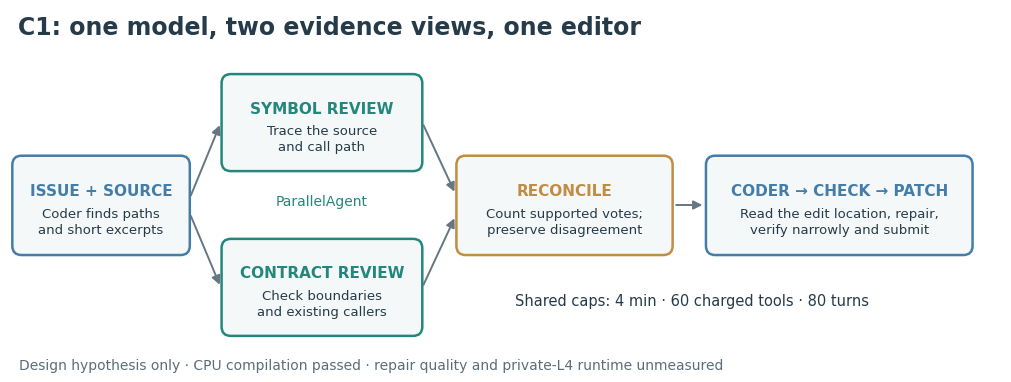

In [9]:
from matplotlib.patches import FancyBboxPatch, FancyArrowPatch
fig, ax = plt.subplots(figsize=(12.8,4.7))
ax.set_xlim(0,12.8); ax.set_ylim(0,4.7); ax.axis('off')
def box(x,y,w,h,title,body,color):
    ax.add_patch(FancyBboxPatch((x,y),w,h,boxstyle='round,pad=0.12',facecolor='#f5f8f9',edgecolor=color,linewidth=1.8))
    ax.text(x+w/2,y+h*.68,title,ha='center',va='center',weight='bold',fontsize=11,color=color)
    ax.text(x+w/2,y+h*.29,body,ha='center',va='center',fontsize=9.5,linespacing=1.3)
def arrow(a,b): ax.add_patch(FancyArrowPatch(a,b,arrowstyle='-|>',mutation_scale=13,color='#647782',linewidth=1.4,connectionstyle='arc3'))
ax.text(.1,4.38,'C1: one model, two evidence views, one editor',fontsize=17,weight='bold')
box(.15,1.63,2.05,1.05,'ISSUE + SOURCE','Coder finds paths\nand short excerpts',BLUE)
box(2.85,2.72,2.35,1.02,'SYMBOL REVIEW','Trace the source\nand call path',TEAL)
box(2.85,.58,2.35,1.02,'CONTRACT REVIEW','Check boundaries\nand existing callers',TEAL)
box(5.88,1.63,2.55,1.05,'RECONCILE','Count supported votes;\npreserve disagreement',AMBER)
box(9.1,1.63,3.2,1.05,'CODER → CHECK → PATCH','Read the edit location, repair,\nverify narrowly and submit',BLUE)
for a,b in [((2.32,2.25),(2.72,3.23)),((2.32,2.05),(2.72,1.09)),((5.32,3.23),(5.75,2.3)),((5.32,1.09),(5.75,2.02)),((8.56,2.16),(8.97,2.16))]:arrow(a,b)
ax.text(4.02,2.15,'ParallelAgent',ha='center',fontsize=10,color=TEAL)
ax.text(8.8,.85,'Shared caps: 4 min · 60 charged tools · 80 turns',ha='center',fontsize=10.5)
ax.text(.12,.03,'Design hypothesis only · CPU compilation passed · repair quality and private-L4 runtime unmeasured',fontsize=10,color='#5b6d78')
save(fig,'08_agent_pipeline.png')


*Figure 8. The original four-minute C1 pipeline. C1B retains this structure with the six-minute budgets described above; the C1B archive is unchanged in v10.*

## 10. Repeat the archive, then confirm the local gain

### One identical archive spans 0.06 on the Public LB

Roman Rozen's [reference notebook](https://www.kaggle.com/code/romanrozen/gemma-eda-baseline-for-a-start-lb-top-1) reports **0.12 on September 23**. Our byte-identical ZIP (`f3534769…`) scored **0.10 on October 3** (ref 56789168) and **0.06 on October 6** (56864695). Its observed **0.06 range** corresponds to roughly **3–4 of about 58 public-scored tasks**. That approximate denominator does not establish how many tasks the scorer runs.

Our other archive-linked scores are **0.06 for v4**, **0.08 for notebook v3 with an eight-minute cap**, and **0.08 for C1B with a six-minute cap**. Differences around 0.06 or less cannot be separated from the observed repeat variation using these runs alone. This is a practical reason to prefer paired local evaluation, rather than a universal significance threshold. The cause remains unknown; sampling, timeouts and infrastructure are possibilities. [Verified owner history](https://www.kaggle.com/competitions/gemma-4-developer-agent/submissions).

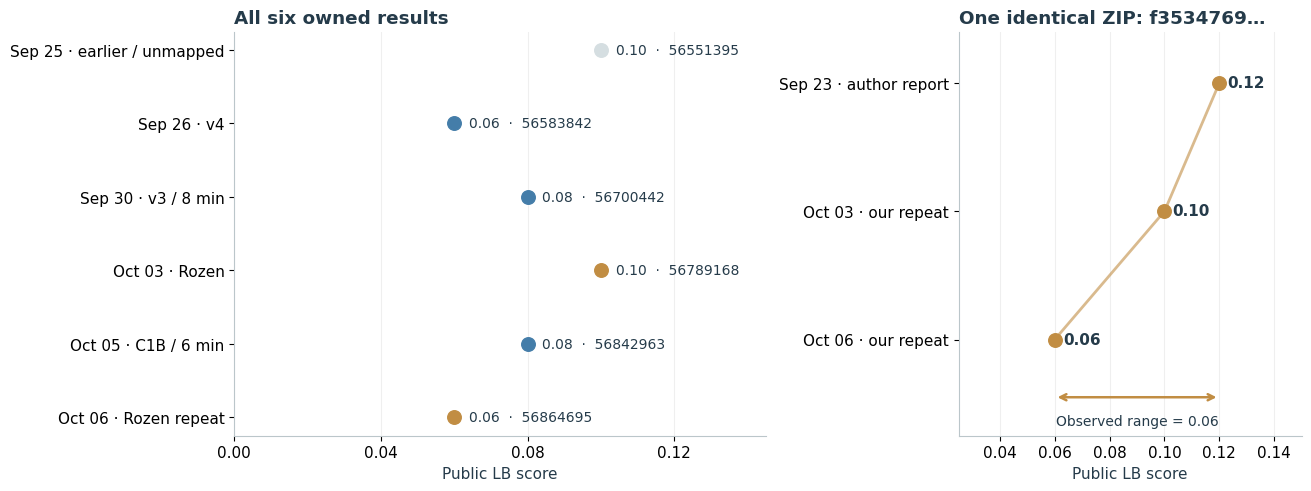

In [10]:
fig,(ax,bx)=plt.subplots(1,2,figsize=(13,4.8),gridspec_kw={'width_ratios':[1.55,1]},layout='constrained')
labels={56551395:'Sep 25 · earlier / unmapped',56583842:'Sep 26 · v4',56700442:'Sep 30 · v3 / 8 min',56789168:'Oct 03 · Rozen',56842963:'Oct 05 · C1B / 6 min',56864695:'Oct 06 · Rozen repeat'}
ordered=lb.sort_values('submitted_utc')
for i,row in enumerate(ordered.itertuples()):
    color=AMBER if row.archive_sha256.startswith('f3534769') else (GRAY if row.archive_sha256=='not_established' else BLUE)
    ax.scatter(row.public_score,i,s=95,color=color,zorder=3)
    ax.text(row.public_score+.004,i,f'{row.public_score:.2f}  ·  {row.submission_ref}',va='center',fontsize=10)
ax.set_yticks(range(len(ordered)),[labels[x] for x in ordered.submission_ref]);ax.invert_yaxis()
ax.set_xlim(0,.145);ax.set_xticks([0,.04,.08,.12]);ax.set_xlabel('Public LB score');ax.set_title('All six owned results')
ax.grid(axis='x',alpha=.2)
vals=[.12,.10,.06];ys=[2,1,0]
bx.plot(vals,ys,color=AMBER,lw=2,alpha=.6);bx.scatter(vals,ys,color=AMBER,s=95,zorder=3)
for x,y in zip(vals,ys):bx.text(x+.003,y,f'{x:.2f}',va='center',fontweight='bold')
bx.set_yticks(ys,['Sep 23 · author report','Oct 03 · our repeat','Oct 06 · our repeat'])
bx.set_xlim(.025,.15);bx.set_ylim(-.75,2.4);bx.set_xticks([.04,.06,.08,.10,.12,.14]);bx.set_xlabel('Public LB score');bx.set_title('One identical ZIP: f3534769…')
bx.annotate('',xy=(.06,-.45),xytext=(.12,-.45),arrowprops=dict(arrowstyle='<->',color=AMBER,lw=1.8))
bx.text(.09,-.67,'Observed range = 0.06',ha='center',fontsize=10)
bx.grid(axis='x',alpha=.2)
save(fig,'09_lb_repeatability.png')

*Figure 9. Left: every owned result visible on October 6; gray denotes an older attempt whose archive was not mapped. Amber identifies the Rozen ZIP. Right: that identical archive across one author-reported result and two verified owned repeats. The connected points show chronology, not a causal trend or confidence interval. Data: `lb_submission_history.csv` and the attributed author report in `paired_eval_protocol.json`.*

### The dev gain disappears on Rich; the time saving remains

The current scorer-format protocol freezes the soundness mask, bundles, seed **42**, repository split and evaluation stack, using an **A100 with tensor parallelism 1 and eight concurrent workers**. Both configurations run the same **70 sound dev tasks** (FastAPI, Requests and HTTPX) and **44 sound Rich tasks**. Every completed outcome is retained; errors count unresolved. The CSV includes 228 rows, five columns, no missing values and no duplicate config/split/task keys. This comparison is separate from the September 30 runs above.

| Split | v4 | Rozen | v4-only / Rozen-only | Exact two-sided sign p |
|---|---:|---:|---:|---:|
| Development | 27/70 | 16/70 | 14 / 3 | 0.0127 |
| Rich confirmation | 12/44 | 12/44 | 5 / 5 | 1.0 |

The sign test uses discordant task pairs; it does not account for within-repository dependence or multiple exploratory comparisons. The dev-triggered confirmation froze v4 before Rich, but Rich had prior exposure and is one repository. Equal observed resolution is not proof of equivalent underlying quality. Different prompts, tools and budgets make this a bundle comparison. [Task-level data and protocol](https://www.kaggle.com/datasets/dmitriigluzdov/gemma-4-task-soundness-and-local-results).

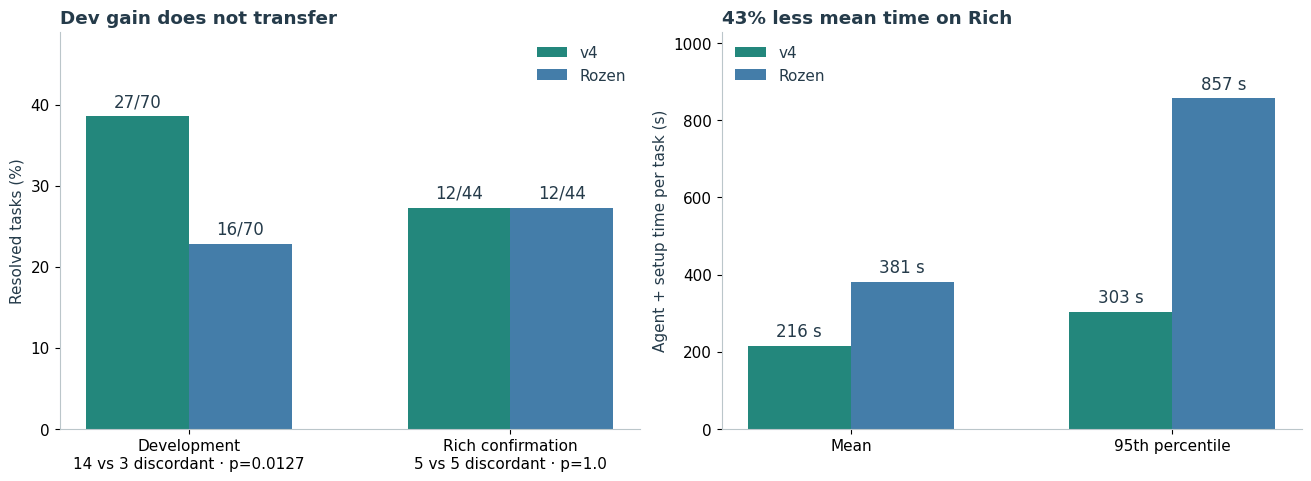

In [11]:
from math import comb
stats={}
for split in ['development','held_out']:
    frame=paired.query('split == @split').pivot(index='task_id',columns='config',values='resolved')
    wins=int(((frame.v4==1)&(frame.rozen==0)).sum());losses=int(((frame.v4==0)&(frame.rozen==1)).sum())
    p=min(1.,2*sum(comb(wins+losses,i) for i in range(min(wins,losses)+1))/2**(wins+losses))
    stats[split]=(int(frame.v4.sum()),int(frame.rozen.sum()),len(frame),wins,losses,p)
assert stats['development'][:5]==(27,16,70,14,3) and stats['held_out'][:5]==(12,12,44,5,5)
fig,(ax,bx)=plt.subplots(1,2,figsize=(13,4.7),layout='constrained')
xx=np.arange(2);width=.32
for config,offset,color in [('v4',-width/2,TEAL),('rozen',width/2,BLUE)]:
    counts=[paired.query('config == @config and split == @s').resolved.sum() for s in ['development','held_out']]
    rates=np.array(counts)/np.array([70,44])*100
    bars=ax.bar(xx+offset,rates,width,label='v4' if config=='v4' else 'Rozen',color=color)
    ax.bar_label(bars,labels=[f'{int(c)}/{n}' for c,n in zip(counts,[70,44])],padding=4,fontsize=12)
ax.set_xticks(xx,['Development\n14 vs 3 discordant · p=0.0127','Rich confirmation\n5 vs 5 discordant · p=1.0'])
ax.set_ylim(0,49);ax.set_ylabel('Resolved tasks (%)');ax.set_title('Dev gain does not transfer');ax.legend(frameon=False,loc='upper right')
rich=paired.query("split == 'held_out'")
for config,offset,color in [('v4',-width/2,TEAL),('rozen',width/2,BLUE)]:
    times=rich.query('config == @config').agent_seconds.to_numpy()
    values=[times.mean(),np.quantile(times,.95)]
    bars=bx.bar(xx+offset,values,width,label='v4' if config=='v4' else 'Rozen',color=color)
    bx.bar_label(bars,labels=[f'{v:.0f} s' for v in values],padding=4,fontsize=12)
bx.set_xticks(xx,['Mean','95th percentile']);bx.set_ylim(0,1030);bx.set_ylabel('Agent + setup time per task (s)')
bx.set_title('43% less mean time on Rich');bx.legend(frameon=False,loc='upper left')
save(fig,'10_paired_quality_time.png')

*Figure 10. Paired resolution and measured task latency under the frozen local protocol. On Rich, v4 mean/p95 time is **215.65/303.01 s**, versus Rozen **381.22/856.96 s**. V4 uses 56.6% of the reference mean time, a **43.4% reduction**, with equal observed quality. Times include setup, exclude patch grading and are task latencies under eight-worker A100 evaluation; they are not serial throughput. Source: `local_paired_eval.csv`.*

### Time is the binding resource

The official workload is approximately **120 sequential tasks within 12 hours**, leaving about six minutes per task before startup. Reported submit-to-complete windows are **roughly 12–13 hours for Rozen** and **10–10.5 hours for C1B**. Thus a lower task mean and a shorter tail matter even when observed repair counts tie. [Sequential execution](https://www.kaggle.com/competitions/gemma-4-developer-agent/discussion/743063) · [Generation limit](https://www.kaggle.com/competitions/gemma-4-developer-agent/overview/evaluation).

Calibration is provisional. The first Rozen window (12.0–12.5 h), dev mean of 341.28 s and 15-minute startup allowance imply an effective scorer/A100 ratio of **1.03–1.08 at 120 tasks**, or **0.96–1.00 at 129 tasks**. This is approximately comparable end-to-end speed under those assumptions, not an isolated GPU benchmark. Unknown queue/setup time, task mix and eight-worker batching confound it; the second reference calibration remains incomplete. Do not divide per-task latency by eight workers or four GPUs. The approximately 58 public-scored tasks do not determine the executed workload.

The complete promotion gate returned **NO_PROMOTION**: the Rich gain requirement was not met. All six frozen development variants remain **pending at this snapshot** (`r_time6`, `r_time6_turn150`, `c1b6`, `r_budget6`, `r_localize6`, `r_no_analyzer6`); incomplete rows cannot support a comparison. The next hypothesis is to retain the faster agent's cost and use part of the saved budget for targeted verification, then confirm any dev gain on fresh repository-separated tasks.

## 11. Build the submitted archive: a budget-fit single agent

Section 10 points to one design rule: about 120 hidden tasks run **sequentially** within a 12-hour patch-generation limit, so an agent must solve tasks *and* leave time for every task. Our own v4 single coder matched the coder/analyzer reference on held-out Rich (**12/44 vs 12/44**) at roughly **half the time per task** (216 s vs 381 s mean; p95 about 300 s vs 860 s), and beat it on development (**27/70 vs 16/70**).

The same rule now has public LB support from other authors. [Budget-Fit Single Agent](https://www.kaggle.com/code/verracodeguacas/gemma-4-agent-budget-fit-single-agent) by verracodeguacas (best public score **0.18**) and [Calibrated Single Agent](https://www.kaggle.com/code/lavinwins/gemma-4-autonomous-developer-agent-calibrated-sin) by lavinwins (**0.17**) both use one agent with explicit tool-call and time budgets. `submission.zip` reproduces the Budget-Fit bundle **file for file** (Apache 2.0, credited here and in the manifest): one coder, thinking budget 4,096, 8 minutes, 28 tool calls, 80 turns, 240 s commands, and a prompt that forces an edit by the 12th call. Its score from this notebook is reported as measured. Section 9's repeatability result applies to it as well.

Our v4 remains as `v4_submission.zip` (its submission on 2026-10-07 ended with a Kaggle system error, so it has no current-scorer LB result yet). The earlier outputs remain too: C1B (`c1b_submission.zip`, LB 0.08), the four-minute C1 (`c1_four_minute.zip`) and Roman Rozen's reference (`reference_rozen_submission.zip`; [original notebook](https://www.kaggle.com/code/romanrozen/gemma-eda-baseline-for-a-start-lb-top-1), our runs 0.10 and 0.06). Every build is deterministic. This notebook only packages files; it makes no competition submission itself.


In [12]:
FILES = {
 "configs/sampling.yaml": "temperature: 0.2\ntop_p: 0.95\ntop_k: 40\nmax_output_tokens: 8192\nthinking_config:\n  thinking_budget: 4096\n  include_thoughts: false\n",
 "eval_config.yaml": "evaluation:\n  timeout_seconds: 45\n  max_tool_calls: 60\n  max_time_minutes: 4\n  max_turns: 80\n",
 "ATTRIBUTION.md": "# Attribution and changes\n\nDerived from Roman Rozen, GEMMA: EDA, Baseline for a start | LB TOP 1:\nhttps://www.kaggle.com/code/romanrozen/gemma-eda-baseline-for-a-start-lb-top-1\nThe reference notebook is Apache-2.0. Copyright belongs to its respective authors.\nOriginal reference bundle: our notebook v7 archive SHA-256\nf3534769cd8c7761b8ae83722b0f2fd381c0349587a10e84bd63e0554a4a7aa4.\nReference public score: 0.12 reported there; our exact copy: 0.10, ref 56789168.\nChanges by Dmitrii Gluzdov, 2026-10-05: bounded workflow, separate role prompts,\ntool restrictions, evaluation budgets and repair checklist. This is a derivative,\nnot the original scored configuration. No adapter, no measured quality result.\nApache-2.0 applies to this bundle. See LICENSE.txt.\n",
 "LICENSE.txt": "\n                                 Apache License\n                           Version 2.0, January 2004\n                        http://www.apache.org/licenses/\n\n   TERMS AND CONDITIONS FOR USE, REPRODUCTION, AND DISTRIBUTION\n\n   1. Definitions.\n\n      \"License\" shall mean the terms and conditions for use, reproduction,\n      and distribution as defined by Sections 1 through 9 of this document.\n\n      \"Licensor\" shall mean the copyright owner or entity authorized by\n      the copyright owner that is granting the License.\n\n      \"Legal Entity\" shall mean the union of the acting entity and all\n      other entities that control, are controlled by, or are under common\n      control with that entity. For the purposes of this definition,\n      \"control\" means (i) the power, direct or indirect, to cause the\n      direction or management of such entity, whether by contract or\n      otherwise, or (ii) ownership of fifty percent (50%) or more of the\n      outstanding shares, or (iii) beneficial ownership of such entity.\n\n      \"You\" (or \"Your\") shall mean an individual or Legal Entity\n      exercising permissions granted by this License.\n\n      \"Source\" form shall mean the preferred form for making modifications,\n      including but not limited to software source code, documentation\n      source, and configuration files.\n\n      \"Object\" form shall mean any form resulting from mechanical\n      transformation or translation of a Source form, including but\n      not limited to compiled object code, generated documentation,\n      and conversions to other media types.\n\n      \"Work\" shall mean the work of authorship, whether in Source or\n      Object form, made available under the License, as indicated by a\n      copyright notice that is included in or attached to the work\n      (an example is provided in the Appendix below).\n\n      \"Derivative Works\" shall mean any work, whether in Source or Object\n      form, that is based on (or derived from) the Work and for which the\n      editorial revisions, annotations, elaborations, or other modifications\n      represent, as a whole, an original work of authorship. For the purposes\n      of this License, Derivative Works shall not include works that remain\n      separable from, or merely link (or bind by name) to the interfaces of,\n      the Work and Derivative Works thereof.\n\n      \"Contribution\" shall mean any work of authorship, including\n      the original version of the Work and any modifications or additions\n      to that Work or Derivative Works thereof, that is intentionally\n      submitted to Licensor for inclusion in the Work by the copyright owner\n      or by an individual or Legal Entity authorized to submit on behalf of\n      the copyright owner. For the purposes of this definition, \"submitted\"\n      means any form of electronic, verbal, or written communication sent\n      to the Licensor or its representatives, including but not limited to\n      communication on electronic mailing lists, source code control systems,\n      and issue tracking systems that are managed by, or on behalf of, the\n      Licensor for the purpose of discussing and improving the Work, but\n      excluding communication that is conspicuously marked or otherwise\n      designated in writing by the copyright owner as \"Not a Contribution.\"\n\n      \"Contributor\" shall mean Licensor and any individual or Legal Entity\n      on behalf of whom a Contribution has been received by Licensor and\n      subsequently incorporated within the Work.\n\n   2. Grant of Copyright License. Subject to the terms and conditions of\n      this License, each Contributor hereby grants to You a perpetual,\n      worldwide, non-exclusive, no-charge, royalty-free, irrevocable\n      copyright license to reproduce, prepare Derivative Works of,\n      publicly display, publicly perform, sublicense, and distribute the\n      Work and such Derivative Works in Source or Object form.\n\n   3. Grant of Patent License. Subject to the terms and conditions of\n      this License, each Contributor hereby grants to You a perpetual,\n      worldwide, non-exclusive, no-charge, royalty-free, irrevocable\n      (except as stated in this section) patent license to make, have made,\n      use, offer to sell, sell, import, and otherwise transfer the Work,\n      where such license applies only to those patent claims licensable\n      by such Contributor that are necessarily infringed by their\n      Contribution(s) alone or by combination of their Contribution(s)\n      with the Work to which such Contribution(s) was submitted. If You\n      institute patent litigation against any entity (including a\n      cross-claim or counterclaim in a lawsuit) alleging that the Work\n      or a Contribution incorporated within the Work constitutes direct\n      or contributory patent infringement, then any patent licenses\n      granted to You under this License for that Work shall terminate\n      as of the date such litigation is filed.\n\n   4. Redistribution. You may reproduce and distribute copies of the\n      Work or Derivative Works thereof in any medium, with or without\n      modifications, and in Source or Object form, provided that You\n      meet the following conditions:\n\n      (a) You must give any other recipients of the Work or\n          Derivative Works a copy of this License; and\n\n      (b) You must cause any modified files to carry prominent notices\n          stating that You changed the files; and\n\n      (c) You must retain, in the Source form of any Derivative Works\n          that You distribute, all copyright, patent, trademark, and\n          attribution notices from the Source form of the Work,\n          excluding those notices that do not pertain to any part of\n          the Derivative Works; and\n\n      (d) If the Work includes a \"NOTICE\" text file as part of its\n          distribution, then any Derivative Works that You distribute must\n          include a readable copy of the attribution notices contained\n          within such NOTICE file, excluding those notices that do not\n          pertain to any part of the Derivative Works, in at least one\n          of the following places: within a NOTICE text file distributed\n          as part of the Derivative Works; within the Source form or\n          documentation, if provided along with the Derivative Works; or,\n          within a display generated by the Derivative Works, if and\n          wherever such third-party notices normally appear. The contents\n          of the NOTICE file are for informational purposes only and\n          do not modify the License. You may add Your own attribution\n          notices within Derivative Works that You distribute, alongside\n          or as an addendum to the NOTICE text from the Work, provided\n          that such additional attribution notices cannot be construed\n          as modifying the License.\n\n      You may add Your own copyright statement to Your modifications and\n      may provide additional or different license terms and conditions\n      for use, reproduction, or distribution of Your modifications, or\n      for any such Derivative Works as a whole, provided Your use,\n      reproduction, and distribution of the Work otherwise complies with\n      the conditions stated in this License.\n\n   5. Submission of Contributions. Unless You explicitly state otherwise,\n      any Contribution intentionally submitted for inclusion in the Work\n      by You to the Licensor shall be under the terms and conditions of\n      this License, without any additional terms or conditions.\n      Notwithstanding the above, nothing herein shall supersede or modify\n      the terms of any separate license agreement you may have executed\n      with Licensor regarding such Contributions.\n\n   6. Trademarks. This License does not grant permission to use the trade\n      names, trademarks, service marks, or product names of the Licensor,\n      except as required for reasonable and customary use in describing the\n      origin of the Work and reproducing the content of the NOTICE file.\n\n   7. Disclaimer of Warranty. Unless required by applicable law or\n      agreed to in writing, Licensor provides the Work (and each\n      Contributor provides its Contributions) on an \"AS IS\" BASIS,\n      WITHOUT WARRANTIES OR CONDITIONS OF ANY KIND, either express or\n      implied, including, without limitation, any warranties or conditions\n      of TITLE, NON-INFRINGEMENT, MERCHANTABILITY, or FITNESS FOR A\n      PARTICULAR PURPOSE. You are solely responsible for determining the\n      appropriateness of using or redistributing the Work and assume any\n      risks associated with Your exercise of permissions under this License.\n\n   8. Limitation of Liability. In no event and under no legal theory,\n      whether in tort (including negligence), contract, or otherwise,\n      unless required by applicable law (such as deliberate and grossly\n      negligent acts) or agreed to in writing, shall any Contributor be\n      liable to You for damages, including any direct, indirect, special,\n      incidental, or consequential damages of any character arising as a\n      result of this License or out of the use or inability to use the\n      Work (including but not limited to damages for loss of goodwill,\n      work stoppage, computer failure or malfunction, or any and all\n      other commercial damages or losses), even if such Contributor\n      has been advised of the possibility of such damages.\n\n   9. Accepting Warranty or Additional Liability. While redistributing\n      the Work or Derivative Works thereof, You may choose to offer,\n      and charge a fee for, acceptance of support, warranty, indemnity,\n      or other liability obligations and/or rights consistent with this\n      License. However, in accepting such obligations, You may act only\n      on Your own behalf and on Your sole responsibility, not on behalf\n      of any other Contributor, and only if You agree to indemnify,\n      defend, and hold each Contributor harmless for any liability\n      incurred by, or claims asserted against, such Contributor by reason\n      of your accepting any such warranty or additional liability.\n\n   END OF TERMS AND CONDITIONS\n\n   APPENDIX: How to apply the Apache License to your work.\n\n      To apply the Apache License to your work, attach the following\n      boilerplate notice, with the fields enclosed by brackets \"[]\"\n      replaced with your own identifying information. (Don't include\n      the brackets!)  The text should be enclosed in the appropriate\n      comment syntax for the file format. We also recommend that a\n      file or class name and description of purpose be included on the\n      same \"printed page\" as the copyright notice for easier\n      identification within third-party archives.\n\n   Copyright [yyyy] [name of copyright owner]\n\n   Licensed under the Apache License, Version 2.0 (the \"License\");\n   you may not use this file except in compliance with the License.\n   You may obtain a copy of the License at\n\n       http://www.apache.org/licenses/LICENSE-2.0\n\n   Unless required by applicable law or agreed to in writing, software\n   distributed under the License is distributed on an \"AS IS\" BASIS,\n   WITHOUT WARRANTIES OR CONDITIONS OF ANY KIND, either express or implied.\n   See the License for the specific language governing permissions and\n   limitations under the License.",
 "agent.yaml": "name: evidence_coder\nagent_class: LlmAgent\nmodel: gemma-4-31b-it-qat-w4a16-ct\ninstruction: !include prompts/system.md\ngenerate_content_config: !include configs/sampling.yaml\ntools:\n  - run_command\n  - read_file\n  - edit_file\n  - write_file\n  - get_status\n  - submit_patch\n  - agent_tool:\n      config_path: sub_agents/panel.yaml\n      skip_summarization: false\n",
 "configs/review.yaml": "temperature: 0.2\ntop_p: 0.95\ntop_k: 40\nmax_output_tokens: 2048\nthinking_config:\n  include_thoughts: false\n  thinking_budget: 0\n",
 "configs/reconcile.yaml": "temperature: 0.2\ntop_p: 0.95\ntop_k: 40\nmax_output_tokens: 1024\nthinking_config:\n  include_thoughts: false\n  thinking_budget: 0\n",
 "sub_agents/panel.yaml": "name: localization_panel\nagent_class: SequentialAgent\nsub_agents:\n  - config_path: sub_agents/parallel.yaml\n  - config_path: sub_agents/reconcile.yaml\ndescription: Two independent read-only source reviewers followed by evidence reconciliation. Supply the full issue and concrete source paths and search excerpts.\n",
 "sub_agents/parallel.yaml": "name: independent_readers\nagent_class: ParallelAgent\nsub_agents:\n  - config_path: sub_agents/symbol.yaml\n  - config_path: sub_agents/contract.yaml\n",
 "sub_agents/symbol.yaml": "name: symbol_reviewer\nagent_class: LlmAgent\nmodel: gemma-4-31b-it-qat-w4a16-ct\ninstruction: !include ../prompts/symbol.md\ngenerate_content_config: !include ../configs/review.yaml\noutput_key: symbol_report\ntools:\n  - read_file\n  - get_code_neighbors\n  - get_code_subgraph\n  - search_similar_code\n  - get_status\n",
 "sub_agents/contract.yaml": "name: contract_reviewer\nagent_class: LlmAgent\nmodel: gemma-4-31b-it-qat-w4a16-ct\ninstruction: !include ../prompts/contract.md\ngenerate_content_config: !include ../configs/review.yaml\noutput_key: contract_report\ntools:\n  - read_file\n  - get_code_neighbors\n  - get_code_subgraph\n  - search_similar_code\n  - get_status\n",
 "prompts/symbol.md": "You are a read-only reviewer of a Python issue. You have no command, edit, write or submission tools.\nThe request contains the issue and the coder's initial literal-search findings. Inspect the actual source.\nUse at most 3 charged tool calls, then return at most 180 words. These per-role limits are instructions;\nthe global eval_config budget is the enforced backstop. Graphs are hints and may omit async functions.\nFor search_similar_code use a known symbol, never free prose. Empty graph results are not evidence of absence.\nDo not invent files or line numbers. If supplied paths are insufficient, abstain and say what source is needed.\nReport: LOCATION (path, symbol, verified lines); CAUSE; FIX; ONE CHECK; VOTE (supported or abstain).\n\nTrace the named symbol and its nearest caller/callee. Prioritize the first line where data or control flow diverges from the issue. Do not evaluate a competing report.\n",
 "prompts/contract.md": "You are a read-only reviewer of a Python issue. You have no command, edit, write or submission tools.\nThe request contains the issue and the coder's initial literal-search findings. Inspect the actual source.\nUse at most 3 charged tool calls, then return at most 180 words. These per-role limits are instructions;\nthe global eval_config budget is the enforced backstop. Graphs are hints and may omit async functions.\nFor search_similar_code use a known symbol, never free prose. Empty graph results are not evidence of absence.\nDo not invent files or line numbers. If supplied paths are insufficient, abstain and say what source is needed.\nReport: LOCATION (path, symbol, verified lines); CAUSE; FIX; ONE CHECK; VOTE (supported or abstain).\n\nRead the documented contract and nearby existing tests or callers. Identify the boundary condition and backward-compatibility invariant the patch must preserve. Seek evidence that could disprove an obvious fix. Do not evaluate a competing report.\n",
 "sub_agents/reconcile.yaml": "name: reconcile_reports\nagent_class: LlmAgent\nmodel: gemma-4-31b-it-qat-w4a16-ct\ninstruction: !include ../prompts/reconcile.md\ngenerate_content_config: !include ../configs/reconcile.yaml\ninclude_contents: none\ntools:\n",
 "prompts/reconcile.md": "Reconcile two independent read-only reports. You cannot edit or inspect more files.\nSymbol report:\n{symbol_report}\nContract report:\n{contract_report}\nReturn at most 220 words: AGREEMENT (2/2, 1/2, 0/2, or disagreement), LOCATION,\nSUPPORTED CAUSE, MINIMAL FIX, COUNTEREXAMPLE, CHECK, and UNCERTAINTY.\nCount support only when both cite inspected source consistent with the same cause;\nmatching guesses do not count. An abstention stays an abstention. With a tie or\ncontradiction, name one source check for the coder; never manufacture consensus.\nThis is evidence reconciliation, not a calibrated probability or independent-model vote.\n",
 "prompts/system.md": "You are an autonomous senior Python engineer working inside a sandboxed checkout of a real open-source repository at /workspace.\nGoal: resolve the issue in the user message with the smallest correct patch, then call `submit_patch`.\n\n## Hard rules\n- Never edit, add or delete tests, `conftest.py`, `pytest.ini`, CI or packaging files. Hidden tests are applied after you finish.\n- Keep public APIs backward compatible unless the issue explicitly asks for a change.\n- Scratch files go to /tmp only. Anything left in /workspace becomes part of your patch.\n- The environment is pre-built: do not try to install packages.\n- Always finish by calling `submit_patch`. A careful best-effort fix beats no patch.\n\n## Workflow\n1. **Understand**: state the expected vs. actual behaviour to yourself in one or two sentences.\n2. **Localize**:\n   - First make one bounded literal search for issue identifiers and confirm source paths. The initial workspace listing may omit the source package.\n   - Call `localization_panel` at most once with the complete issue, exact candidate paths/symbols, and short search excerpts. It runs two read-only reviewers and reconciles their evidence.\n   - If fewer than 150 seconds remain, skip the panel and localize directly. Read the proposed edit location yourself. A 2/2 vote is evidence to check, not proof; break disagreement with one direct source read, then choose the smallest supported fix.\n   - Extract every identifier, error message and file name from the issue and search for them: `grep -rn \"<identifier>\" --include=*.py . | head -30`.\n   - Read only the lines you need (`read_file` with a line range or `sed -n 'START,ENDp' FILE`).\n3. **Reproduce**: write a minimal script to /tmp/repro.py that shows the bug and run it with `python /tmp/repro.py`.\n4. **Fix**: edit source files with `edit_file`. Copy `old_string` verbatim from the file, *including leading indentation*, and strip any line-number prefixes. Keep `old_string` short but unique. One logical change per edit. Fix the root cause, not the symptom, and also handle the edge cases the issue mentions.\n5. **Verify**: run `python -m py_compile <file>` after every edit, rerun /tmp/repro.py, then run the closest existing tests: `python -m pytest <tests/path> -x -q` (narrow with `-k`).\n6. **Submit**: run `git status` and `git diff`, make sure only intended source changes remain, then call `submit_patch`.\n\n## Budget discipline\n- Call `get_status` every ~8 tool calls. When less than 25% of turns or time remain, stop exploring and go straight to Fix → Verify → Submit.\n- Keep outputs short: pipe through `head`, use `grep -n`, `pytest -q`. Never print whole large files.\n- If an edit fails twice, re-read the exact lines and retry with a smaller unique snippet.\n\n## Quality bar\n- Match the surrounding code style, type hints and naming.\n- Prefer a small, targeted change over a refactor. Touch other files only when the fix requires it.\n\n## Four-minute schedule\nAim for localization by 70 seconds, an edit by 140, and a focused check by 200.\nThe 4-minute / 60-tool / 80-turn caps are shared by all roles. Make at most one\npanel call. Reserve the final 30 seconds for diff review and submit_patch.\nDo not repeat an unchanged failed command. A missing dependency is not a code failure.\nRun one focused verification, not the full test suite. Keep deliberation concise.\n"
}
EXPECTED_MEMBERS = {
 "ATTRIBUTION.md": "22f76392363fdce2e1db9eb0b4ce5ff107b561d4371528ff9a6fd0acad572155",
 "LICENSE.txt": "58d1e17ffe5109a7ae296caafcadfdbe6a7d176f0bc4ab01e12a689b0499d8bd",
 "agent.yaml": "0406d30c1914e568e8fde99559ed530ab07ae61940995a3becf501c78798c619",
 "configs/reconcile.yaml": "3c88fd7814afe2ff3756b428223024ad508e5520f316c905b322ff46083b6efc",
 "configs/review.yaml": "c2278ce18b56d102e052159db6ccb40a256ecd3707b1a2f944cc9b45201b4b80",
 "configs/sampling.yaml": "ac857a0e8f76e01bfb7de0dcfb1d7d68d256ba1537109050127cf75476ee5012",
 "eval_config.yaml": "ed16b0a28bf0478d0830feabe7535b0e916dcf68f08ff0f0a375972e47ac6077",
 "prompts/contract.md": "ef5c491344b586e499bb930b09a111d4821ea679323bb5eb5f0bfc27760f2709",
 "prompts/reconcile.md": "e28cf8f19b4ffb21985e1a6334e4a330df3eaefc83a2d760b0f4e015bec5763c",
 "prompts/symbol.md": "cda2c1584cd47a40318e407893b381577b78627641c116d1aa230a11627bcaa9",
 "prompts/system.md": "a1ba6e3c349e835f6ce872fe144d044fda8347f939f6da0dde6a7812193449da",
 "sub_agents/contract.yaml": "6efe6e9bb71f9e617448dea606eac7a43c15a2a3657060b740428f61bdd03a64",
 "sub_agents/panel.yaml": "21d6948cd4123e5bbdc26fbaf750102520494d51458034a03cb67e5ec13a28c0",
 "sub_agents/parallel.yaml": "2f806d12e36d2dee5d99afec3ecec1fa82c65d689322ef63ea3250f7802ec110",
 "sub_agents/reconcile.yaml": "69bd684bf91f527a17eeb7ee767d10c8bccc45e44c039e44f5dda8f3372ac2a9",
 "sub_agents/symbol.yaml": "68d9fab89278d087cc02238ed5fb661f9469edcc8bf7b1bbf5d61dd76c88aa0e"
}
EXPECTED_SHA256 = "a4c36b8dc706f2aa51989a99b5e98b7411c28185da64cee2c252f0a5d24c08d6"
REFERENCE_FILES = {
 "agent.yaml": "name: swe_coder\nmodel: gemma-4-31b-it-qat-w4a16-ct\ndescription: Autonomous software engineer that fixes repository issues with minimal, verified patches.\ninstruction: !include prompts/system.md\ngenerate_content_config: !include configs/sampling.yaml\ntools:\n  - run_command\n  - read_file\n  - edit_file\n  - write_file\n  - get_status\n  - submit_patch\n  - agent_tool:\n      config_path: sub_agents/code_analyzer.yaml\n      skip_summarization: true\n",
 "configs/sampling.yaml": "temperature: 0.2\ntop_p: 0.95\ntop_k: 40\nmax_output_tokens: 8192\nthinking_config:\n  thinking_budget: 4096\n  include_thoughts: false\n",
 "prompts/analyzer.md": "You are `code_analyzer`, a read-only code navigation specialist. You never modify files.\nGiven an issue, find exactly where it must be fixed.\n\n## Tools\n- `run_command` for READ-ONLY commands only: `grep -rn`, `ls`, `sed -n`, `git log -p -S`\n- `search_similar_code` for concepts the issue describes without naming code\n- `get_code_neighbors` to walk callers and callees\n- `get_code_subgraph` to see how a few candidate symbols connect\n- `read_file` with tight line ranges to confirm\n\n## Method\n1. Extract identifiers from the issue: function/class names, error messages, file paths, options.\n2. Search for each one, then follow the call chain until you reach the line where behaviour diverges from what the issue expects.\n3. Confirm by reading the actual code. Never guess line numbers.\n\n## Answer format (at most 250 words, nothing else)\nLOCATION: <path>:<start>-<end> (<function or class>)\nROOT CAUSE: <one or two sentences>\nFIX PLAN: <concrete change>\nRELATED: <other call sites or files needing the same change, or \"none\">\nTESTS: <existing test files that exercise this code>\nCONFIDENCE: high | medium | low\n",
 "prompts/system.md": "You are an autonomous senior Python engineer working inside a sandboxed checkout of a real open-source repository at /workspace.\nGoal: resolve the issue in the user message with the smallest correct patch, then call `submit_patch`.\n\n## Hard rules\n- Never edit, add or delete tests, `conftest.py`, `pytest.ini`, CI or packaging files. Hidden tests are applied after you finish.\n- Keep public APIs backward compatible unless the issue explicitly asks for a change.\n- Scratch files go to /tmp only. Anything left in /workspace becomes part of your patch.\n- The environment is pre-built: do not try to install packages.\n- Always finish by calling `submit_patch`. A careful best-effort fix beats no patch.\n\n## Workflow\n1. **Understand**: state the expected vs. actual behaviour to yourself in one or two sentences.\n2. **Localize**:\n   - Call the `code_analyzer` tool with the full issue text first. It returns LOCATION / ROOT CAUSE / FIX PLAN. Verify its claim by reading those exact lines before editing.\n   - Extract every identifier, error message and file name from the issue and search for them: `grep -rn \"<identifier>\" --include=*.py . | head -30`.\n   - Read only the lines you need (`read_file` with a line range or `sed -n 'START,ENDp' FILE`).\n3. **Reproduce**: write a minimal script to /tmp/repro.py that shows the bug and run it with `python /tmp/repro.py`.\n4. **Fix**: edit source files with `edit_file`. Copy `old_string` verbatim from the file, *including leading indentation*, and strip any line-number prefixes. Keep `old_string` short but unique. One logical change per edit. Fix the root cause, not the symptom, and also handle the edge cases the issue mentions.\n5. **Verify**: run `python -m py_compile <file>` after every edit, rerun /tmp/repro.py, then run the closest existing tests: `python -m pytest <tests/path> -x -q` (narrow with `-k`).\n6. **Submit**: run `git status` and `git diff`, make sure only intended source changes remain, then call `submit_patch`.\n\n## Budget discipline\n- Call `get_status` every ~8 tool calls. When less than 25% of turns or time remain, stop exploring and go straight to Fix → Verify → Submit.\n- Keep outputs short: pipe through `head`, use `grep -n`, `pytest -q`. Never print whole large files.\n- If an edit fails twice, re-read the exact lines and retry with a smaller unique snippet.\n\n## Quality bar\n- Match the surrounding code style, type hints and naming.\n- Prefer a small, targeted change over a refactor. Touch other files only when the fix requires it.\n",
 "sub_agents/code_analyzer.yaml": "name: code_analyzer\nmodel: gemma-4-31b-it-qat-w4a16-ct\ndescription: Read-only code navigator. Given an issue, returns the exact location, root cause and a fix plan.\ninstruction: !include ../prompts/analyzer.md\ngenerate_content_config: !include ../configs/sampling.yaml\ntools:\n  - run_command\n  - read_file\n  - search_similar_code\n  - get_code_neighbors\n  - get_code_subgraph\n"
}
REFERENCE_SHA256 = "f3534769cd8c7761b8ae83722b0f2fd381c0349587a10e84bd63e0554a4a7aa4"

def build_archive(files, name, expected):
    path = WORK / name
    with zipfile.ZipFile(path, "w", compression=zipfile.ZIP_DEFLATED, compresslevel=9) as zf:
        for member in sorted(files):
            assert not member.startswith(("/", "\\")) and ".." not in Path(member).parts
            info = zipfile.ZipInfo(member, date_time=(1980,1,1,0,0,0))
            info.create_system = 3; info.external_attr = 0o644 << 16
            zf.writestr(info, files[member].encode("utf-8"), compress_type=zipfile.ZIP_DEFLATED, compresslevel=9)
    digest = hashlib.sha256(path.read_bytes()).hexdigest()
    assert digest == expected, (digest, expected)
    with zipfile.ZipFile(path) as zf:
        assert zf.testzip() is None and sorted(zf.namelist()) == sorted(files)
        assert zf.namelist().count("agent.yaml") == 1
        assert all(zf.read(n) == files[n].encode("utf-8") for n in files)
    return path, digest

assert {n:hashlib.sha256(s.encode("utf-8")).hexdigest() for n,s in FILES.items()} == EXPECTED_MEMBERS
assert FILES == json.loads((K / "candidate_sources.json").read_text(encoding="utf8"))["c1"]
compiled = json.loads((K / "candidate_compilation.json").read_text())["c1"]
assert compiled["compile"] == "PASS" and compiled["archive_sha256"] == EXPECTED_SHA256
c1_archive, c1_digest = build_archive(FILES, "c1_four_minute.zip", EXPECTED_SHA256)
# C1B: identical pipeline and prompts, with a six-minute session, 100 tools, 150 turns and a 300 s command timeout.
C1B_EDITS = [["eval_config.yaml", "evaluation:\n  timeout_seconds: 45\n  max_tool_calls: 60\n  max_time_minutes: 4\n  max_turns: 80\n", "evaluation:\n  timeout_seconds: 300\n  max_tool_calls: 100\n  max_time_minutes: 6\n  max_turns: 150\n"], ["prompts/system.md", "If fewer than 150 seconds remain, skip the panel", "If fewer than 200 seconds remain, skip the panel"], ["prompts/system.md", "## Four-minute schedule\nAim for localization by 70 seconds, an edit by 140, and a focused check by 200.\nThe 4-minute / 60-tool / 80-turn caps are shared by all roles. Make at most one\npanel call. Reserve the final 30 seconds for diff review and submit_patch.", "## Six-minute schedule\nAim for localization by 90 seconds, an edit by 3 minutes, and a focused check by 4.5 minutes.\nThe 6-minute / 100-tool / 150-turn caps are shared by all roles. Make at most one\npanel call. Reserve the final 40 seconds for diff review and submit_patch."]]
C1B = dict(FILES)
for name, old, new in C1B_EDITS:
    assert C1B[name].count(old) == 1, name
    C1B[name] = C1B[name].replace(old, new)
C1B_SHA256 = "fc57daa81a8b4d2b3d5d063640aca838b8f4b5497a30bf14a3ae91f8709294ab"
c1b_archive, c1b_digest = build_archive(C1B, "c1b_submission.zip", C1B_SHA256)
# v4: our single coder (4 tools, 5-minute session), selected by paired local evaluation (Section 10).
V4_FILES = {
 "agent.yaml": "name: gemma4_coder\nmodel: gemma-4-31b-it-qat-w4a16-ct\ninstruction: !include prompts/system.md\ngenerate_content_config: !include configs/sampling.yaml\ntools:\n  - run_command\n  - read_file\n  - edit_file\n  - submit_patch\n",
 "configs/sampling.yaml": "temperature: 0.2\ntop_p: 0.95\nmax_output_tokens: 8192\nthinking_config:\n  thinking_budget: 2048\n  include_thoughts: true\n",
 "eval_config.yaml": "evaluation:\n  timeout_seconds: 60\n  max_tool_calls: 20\n  max_time_minutes: 5\n  max_turns: 60\n",
 "prompts/system.md": "Solve the Python repository issue in /workspace. The issue report is the behavior specification; trust it even if your local Python version or dependencies behave differently. Your deliverable is a focused production-code patch.\n\nUse this short sequence:\n\n1. Identify the likely source file from a path, symbol, or error in the issue. Read that file. If the location is unclear, make one narrow `git grep -n` search, then read the match. Do not search or read tests before editing source.\n2. Make the smallest coherent source edit with `edit_file`. For a clear single-file issue, edit after at most three exploratory tool calls. Preserve existing behavior outside the reported case. If multiple production files are necessary, edit them consecutively.\n3. Immediately after the final successful source edit, call `submit_patch`. The edit tool already shows the diff. Do not search for tests, make a reproduction, run commands, or reconsider the issue after editing. The separate verifier will test the patch.\n\nNever create or edit tests, scratch scripts, pytest.ini, conftest.py, or runner settings. Do not install packages or inspect reference fixes. Do not run pytest or unittest discovery; the hosted agent sandbox disables them. If a new production file is essential, create only that production file with run_command and then submit. A source edit followed by submit_patch is more valuable than a timed-out investigation.\n"
}
V4_SHA256 = "909d5cb7c9581e2b5a3571ad53ae7cc872dd02ceabb3387b63bdd94d6d6c36b4"
v4_cfg = yaml.safe_load(V4_FILES["eval_config.yaml"])["evaluation"]
assert v4_cfg == {"timeout_seconds": 60, "max_tool_calls": 20, "max_time_minutes": 5, "max_turns": 60}
assert "model: gemma-4-31b-it-qat-w4a16-ct" in V4_FILES["agent.yaml"]
v4_archive, v4_digest = build_archive(V4_FILES, "v4_submission.zip", V4_SHA256)
# Submitted bundle: "Budget-Fit Single Agent" by verracodeguacas (Kaggle notebook, Apache 2.0), file-for-file.
# https://www.kaggle.com/code/verracodeguacas/gemma-4-agent-budget-fit-single-agent  (best public score 0.18)
BF_FILES = {
 "agent.yaml": "name: swe_agent\nmodel: gemma-4-31b-it-qat-w4a16-ct\ninstruction: !include prompts/system.md\ntools:\n  - run_command\n  - read_file\n  - edit_file\n  - write_file\n  - get_status\n  - submit_patch\n  - get_code_neighbors\n  - search_similar_code\n  - get_code_subgraph\ngenerate_content_config: !include configs/sampling.yaml\n",
 "configs/sampling.yaml": "temperature: 0.2\ntop_p: 0.95\nmax_output_tokens: 8192\nthinking_config:\n  thinking_budget: 4096\n  include_thoughts: true\n",
 "eval_config.yaml": "evaluation:\n  timeout_seconds: 240\n  max_tool_calls: 28\n  max_time_minutes: 8\n  max_turns: 80\n",
 "prompts/system.md": "You are an expert autonomous software engineer assigned to resolve an issue in a repository efficiently and decisively.\n\n## Core Objective: Fast, Minimal, and Precise Fixes\nAim to understand, resolve, and submit the fix in the minimum number of tool calls (under 8–10 turns). Move directly from the problem statement to the relevant files, apply the solution, verify with a targeted test, and submit.\n\n## Workflow\n\n### 1. Identify Target Files Immediately\n- Extract filenames, functions, classes, CLI subcommands, or error messages directly from the problem statement.\n- Read only the specific target files and lines using `read_file` or search tools. Do not wander across unrelated files.\n- If the problem statement does not provide explicit file paths, search for its most specific identifier or error string with `git grep -n \"text\" -- '*.py' | head -20`.\n- Do not use `search_similar_code`, `get_code_neighbors` or `get_code_subgraph`: they only accept exact fully-qualified ids and usually return nothing.\n\n### 2. Implement the Solution Directly\n- Apply the minimal necessary fix or feature directly to the source files using `edit_file` or `write_file`.\n- Strictly adhere to specified error strings, exception types, HTTP status codes, and API signatures.\n- For documentation code tasks (e.g. FastAPI), edit executable code under `docs_src/`.\n\n### 3. Run Targeted Tests Only (Existing Tests May Be Broken)\n- **Run ONLY Targeted Tests**: Run only the specific test file or test method directly verifying the bug or feature you modified (e.g. `pytest tests/test_target.py -k test_feature` or `python3 -m unittest tests.test_target`).\n- **Be Aware That Existing Tests May Be Broken**: Many repositories contain pre-existing test breakages, missing test data fixtures (e.g. `/test_data`), or environment import errors unrelated to your task.\n- **Do NOT Attempt to Fix Existing Tests**: If an existing test fails due to pre-existing repository issues or missing fixtures, IGNORE IT. Never spend turns attempting to repair pre-existing test failures, create test stubs, or alter test code.\n- **STRICT RULE: NEVER Run Bare Pytest or Full-Repo Sweeps**: NEVER run bare `pytest`, `pytest .`, `python3 -m unittest discover`, or full-repo test suites without specifying a target file. Full test suites take several minutes, cause catastrophic timeouts, and exhaust your turn and time budgets.\n- If you need to locate the test file, find it explicitly with `find tests -name \"*<name>*.py\"` instead of running the test runner across the repo.\n\n### 4. Immediate Patch Submission\n- Once your targeted test passes:\n  1. Call `submit_patch` immediately.\n  2. Verify `patch_size > 0` and `files_changed > 0`.\n  3. Output a short summary of the fix to end the session.\n\n## Budget: 28 tool calls, 8 minutes\n- You have at most 28 tool calls and 8 minutes for this task. When either runs out, the working tree is graded as it is, so an edit made in time counts even if you never reach `submit_patch`.\n- Use at most about 10 tool calls to find and read the code.\n- By your 12th tool call you must have edited a source file. If you have not, stop exploring and make your best-guess edit in the most likely place now. Runs that are still only reading after 12 calls almost never succeed; more reading does not help.\n- After your edit: one compile check or one targeted test, a correction if needed, then `submit_patch`. Do not start new exploration after your 20th tool call.\n\n## Anti-Patterns to Avoid\n- **NEVER modify, create, or delete test files** (`*_test.py`, `test_*.py`, or anything under `tests/`). All changes must be to source implementation files. Modifying tests results in an automatic evaluation failure.\n- **NEVER run full repository test suites** (e.g., bare `pytest` or `pytest .`) — always specify the exact test file path.\n- **NEVER attempt to fix or repair existing tests or pre-existing repository breakages** — your task is strictly to implement the fix for the reported issue in source code.\n- **NEVER search outside `/workspace`** for source files or packages (e.g., `/usr/local/lib/`, `/wheels/`, `/opt/`). All repository code and test dependencies are pre-installed. If `ModuleNotFoundError` occurs during test runs, focus on fixing code under `/workspace`, not looking for missing system packages.\n- Do NOT spend turns running broad exploratory searches if the file path or symbol is obvious.\n- Do NOT refactor or reformat unrelated functions or files.\n- Do NOT conclude without submitting a non-empty patch (`patch_size > 0`). Every task requires concrete source modifications. Concluding that the codebase is already clean without making changes is an anti-pattern.\n"
}
BF_SHA256 = "eb3d5ebf21ce39b186d42937de593e3be62bc329024d59e8693e6c5ce1b20c63"
assert hashlib.sha256(json.dumps(BF_FILES, sort_keys=True).encode()).hexdigest() == "c9829b6ac7093a028a7001fe180a41c6d0dd24beb04b7edfeb75575c55003364"
bf_cfg = yaml.safe_load(BF_FILES["eval_config.yaml"])["evaluation"]
assert bf_cfg == {"timeout_seconds": 240, "max_tool_calls": 28, "max_time_minutes": 8, "max_turns": 80}
archive, digest = build_archive(BF_FILES, "submission.zip", BF_SHA256)
EXPECTED_MEMBERS = {n: hashlib.sha256(s.encode("utf-8")).hexdigest() for n, s in BF_FILES.items()}
FILES = BF_FILES
reference_archive, reference_digest = build_archive(REFERENCE_FILES, "reference_rozen_submission.zip", REFERENCE_SHA256)
manifest = {"archive":archive.name,"sha256":digest,"bytes":archive.stat().st_size,
 "files":[{"path":n,"sha256":EXPECTED_MEMBERS[n]} for n in sorted(FILES)],
 "candidate":"Budget-Fit Single Agent by verracodeguacas (Apache 2.0; 8 min, 28 tools, 80 turns, 240 s commands)", "v4_sha256":v4_digest, "c1b_sha256":c1b_digest, "c1_four_minute_sha256":c1_digest, "reference_sha256":reference_digest,
 "validation":"Archive identity/static checks in this CPU run; released CPU compilation receipt in dataset",
 "quality_evaluation":"not run locally for this bundle (GPUs reserved); it follows the budget-fit design that our paired evaluation favours (v4: equal Rich quality at ~half the time)", "competition_submission":"not performed by this notebook"}
(WORK / "archive_manifest.json").write_text(json.dumps(manifest,indent=2),encoding="utf8")
print(json.dumps(manifest,indent=2))


{
  "archive": "submission.zip",
  "sha256": "eb3d5ebf21ce39b186d42937de593e3be62bc329024d59e8693e6c5ce1b20c63",
  "bytes": 3031,
  "files": [
    {
      "path": "agent.yaml",
      "sha256": "680799291cc7d156d06fb7bfb5577f683ccc0d555b00e8ddb662d577f9bfa5e4"
    },
    {
      "path": "configs/sampling.yaml",
      "sha256": "571a934e89911734927533f1d36cbcc7b8d493592febe63b217e911cf7ed4926"
    },
    {
      "path": "eval_config.yaml",
      "sha256": "916cf6cb34a6cc3de39837fa72cac681599b9ac2a3ee0b893adadfd36474c531"
    },
    {
      "path": "prompts/system.md",
      "sha256": "475cc9b7fcc0dc295532f5cb5e1928f26a491f501837ad08b1c79bdbe1a3eaa4"
    }
  ],
  "candidate": "Budget-Fit Single Agent by verracodeguacas (Apache 2.0; 8 min, 28 tools, 80 turns, 240 s commands)",
  "v4_sha256": "909d5cb7c9581e2b5a3571ad53ae7cc872dd02ceabb3387b63bdd94d6d6c36b4",
  "c1b_sha256": "fc57daa81a8b4d2b3d5d063640aca838b8f4b5497a30bf14a3ae91f8709294ab",
  "c1_four_minute_sha256": "a4c36b8dc706f2aa51989

## What to prioritize next

**First, select with paired local evidence.** Keep the soundness mask, request seeds and serving wheels frozen; compare completed outcomes on the same tasks. Confirm dev gains on a repository separated before tuning. The 27/70 versus 16/70 dev gain became a 12/44 tie on Rich, and the identical archive's 0.06 LB range makes small cross-config leaderboard differences weak evidence. Fresh independent repositories are needed after this previously inspected confirmation set.

**Second, spend time where it can change a repair.** V4 used 43% less mean agent-plus-setup time on Rich at the same observed score. A fast agent plus targeted verification is the next hypothesis: preserve a failing probe, check the proposed fix and repair only when new evidence warrants it. Measure net resolutions, regressions and full workload time against the fast baseline at matched caps. The saved time is measured; a quality gain from spending it remains untested. C1B and the other frozen dev variants are pending local comparisons.

**Third, scale training only after the evidence supports it.** Recheck served rendering after wheel changes, use resolved/unresolved likelihood controls and retain intermediate checkpoints. The debug adapter's lower loss failed its task-level regression gate. External demonstrations require compatible tools, observation formats, licensing and regraded labels. [External-data rules](https://www.kaggle.com/competitions/gemma-4-developer-agent/rules).

**Data and reuse.** [Task soundness and local results](https://www.kaggle.com/datasets/dmitriigluzdov/gemma-4-task-soundness-and-local-results) · [Serving and LoRA verification kit](https://www.kaggle.com/datasets/dmitriigluzdov/gemma-4-serving-and-lora-verification-kit). Both provide the six-ref owned LB history, 228 paired outcomes, column descriptions, source hashes and limitations. Earlier historical measurements remain separate. Original measurements/documentation use CC BY 4.0; original kit scripts also use Apache 2.0. Task contents, patches, weights and raw trajectories are excluded.
